# 4.1  Overview of Runs

## Set Up

In [2]:
%matplotlib inline
import json
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

In [3]:
P1 = ['task1','task2','task3','task4','task5','task6']
P2 = ['task7','task8','task9','task10','task11']

GSD_BLUE   = '#2563EB'
WIG_AMBER  = '#D97706'
FAIL_RED   = '#EF4444'
LIGHT_GREY = '#F3F4F6'
MID_GREY   = '#9CA3AF'
DARK_GREY  = '#374151'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
})

In [4]:
# phase 1 task type mappings
frontend_task_types = {
    'task1': 'Feature Implementation',
    'task2': 'Logical Bug Fix',
    'task3': 'Syntax Bug Fix',
    'task4': 'Refactoring',
    'task5': 'Test Generation',
    'task6': 'Integration'
}

backend_task_types = {
    'task1': 'API Contract Fix',
    'task2': 'Service Layer Refactor',
    'task3': 'Test Generation',
    'task4': 'Config & Build Fix',
    'task5': 'Data & Model Update',
    'task6': 'Security & Validation'
}

# task type mappings for phase 2
frontend_task_types_p2 = {
    'task7': 'Context Migration',
    'task8': 'Debounce Implementation',
    'task9': 'Optimistic UI Revert',
    'task10': 'Focus Management',
    'task11': 'Derived State Correctness'
}

backend_task_types_p2 = {
    'task7': 'Route Registration Order',
    'task8': 'Middleware Composition',
    'task9': 'Database Integrity',
    'task10': 'Pagination Correctness',
    'task11': 'Rate Limiter Memory & Header'
}

# task type mapping for phase 3

phase3_task_types = {
    'task12': 'Authentication',
    'task13': 'Profile management'
}

In [5]:
file_path = Path("C:/Users/Rhea/Documents/all-runs-summary-2026-09-26.csv")
df = pd.read_csv(file_path)

df['phase'] = df['taskId'].apply(lambda t: 'Phase 1' if t in P1 else ('Phase 2' if t in P2 else 'Phase 3'))

print(df['buildSuccess'].value_counts())
print(df['phase'].value_counts())
print(df.shape)

# Fix decimal separator issue in numeric columns
# numeric_cols = ['correctness', 'quality', 'overall', 'cost_usd']
# for col in numeric_cols:
#     df[col] = df[col].astype(str).str.replace(',', '.').astype(float)

# df['build_success'] = df['build_success'].astype(str).str.strip().map({'True': True, 'False': False})

print(df['buildSuccess'].unique())
df.head()
# print(df['correctnessScore'].dtype)
# print(df['correctnessScore'].head(10))

buildSuccess
True     259
False      1
Name: count, dtype: int64
phase
Phase 1    120
Phase 2    100
Phase 3     40
Name: count, dtype: int64
(260, 32)
[ True False]


,branch,taskId,runId,resultDir,framework,target,overallSuccess,buildSuccess,buildRawSuccess,visiblePassed,...,qualityScore,overallScore,costUsd,numTurns,wallDurationMs,agentExitCode,agentIsError,totalMs,timestamp,phase
0,run/gsd/task10/gsd-run1,task10,gsd-run1,task10__gsd-run1,gsd,backend,True,True,True,21,...,0.96,0.984,2.308791,71,906324,0,False,4721,2026-09-22T08:15:46.266Z,Phase 2
1,run/gsd/task10/gsd-run1,task10,gsd-run1,task10__gsd-run1,gsd,frontend,False,True,False,29,...,0.57,0.768,3.916710,101,1308876,0,False,9749,2026-09-20T17:14:03.079Z,Phase 2
2,run/gsd/task10/gsd-run2,task10,gsd-run2,task10__gsd-run2,gsd,backend,True,True,True,21,...,0.96,0.984,3.737857,124,1355621,0,False,7587,2026-09-22T08:47:36.383Z,Phase 2
3,run/gsd/task10/gsd-run2,task10,gsd-run2,task10__gsd-run2,gsd,frontend,False,True,False,22,...,0.60,0.780,2.303665,70,625340,0,False,4473,2026-09-20T17:25:58.803Z,Phase 2
4,run/gsd/task10/gsd-run3,task10,gsd-run3,task10__gsd-run3,gsd,backend,True,True,True,21,...,0.96,0.984,1.910276,66,509121,0,False,5030,2026-09-22T09:13:56.735Z,Phase 2


## Phase 1 build success rate

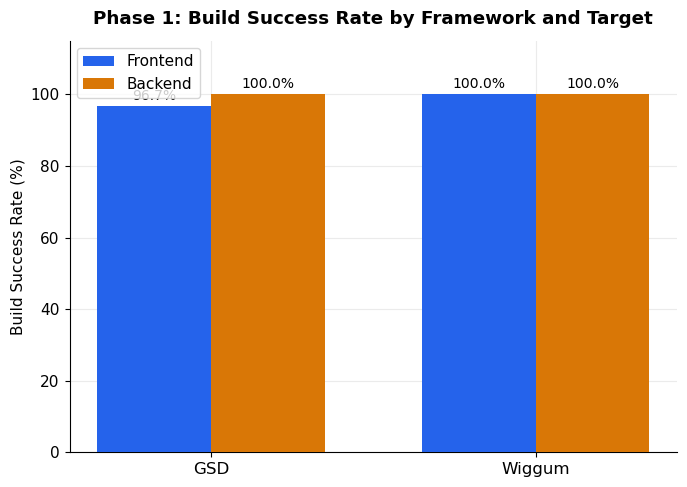

In [6]:
p1 = df[df['phase'] == 'Phase 1']

build_rates_p1 = (
    p1.groupby(['framework', 'target'])['buildSuccess']
    .mean()
    .mul(100)
    .unstack('target')
)

fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(len(build_rates_p1))
width = 0.35

bars_fe = ax.bar(x - width/2, build_rates_p1['frontend'], width,
                 label='Frontend', color=GSD_BLUE, zorder=3)

bars_be = ax.bar(x + width/2, build_rates_p1['backend'], width,
                 label='Backend', color=WIG_AMBER, zorder=3)

for bar in bars_fe:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)

for bar in bars_be:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(['GSD', 'Wiggum'], fontsize=12)
ax.set_ylabel('Build Success Rate (%)')
ax.set_ylim(0, 115)
ax.set_title('Phase 1: Build Success Rate by Framework and Target', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

Both frameworks were reliable at this tier, but the pattern of where failures occurred differs. Wiggum achieved a clean 100% build success rate across both frontend and backend tasks, with no failures in either 30-run set. GSD matched that on the backend (100%) but dropped to 96.7% on the frontend, equivalent to a single build failure out of 30 runs.

This appears to be a narrow, single-instance gap rather than a systemic one. At 96.7%, GSD is one failed run away from parity with Wiggum, so it doesn't yet support a claim that GSD's specification-and-verification approach is structurally weaker on frontend work. It's also worth noting this cuts against the assumption that heavier upfront scaffolding should reduce build failures relative to a restart-based loop. Here the lighter-weight framework was the one with zero build breaks.

Given the low task and run count at this tier, and that Phase 1 was already flagged as too simple to meaningfully differentiate the two frameworks, this single discrepancy is likely noise rather than signal. Whether it recurs or reverses at higher complexity is something Phase 2's frontend tasks (state architecture, async error handling, accessibility) should help clarify, since they're designed to stress exactly the kind of reasoning that a single early build failure can't yet speak to.

## Phase 2 Build Success Rate

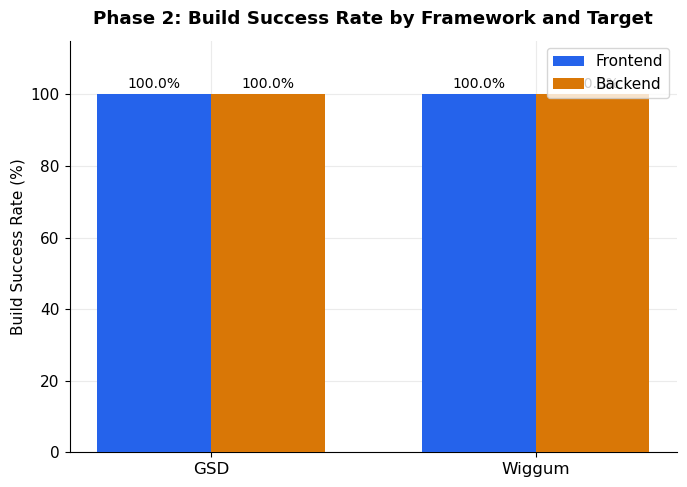

In [7]:
p2 = df[df['phase'] == 'Phase 2']

build_rates_p2 = (
    p2.groupby(['framework', 'target'])['buildSuccess']
    .mean()
    .mul(100)
    .unstack('target')
)

fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(len(build_rates_p2))
width = 0.35

bars_fe = ax.bar(x - width/2, build_rates_p2['frontend'], width,
                 label='Frontend', color=GSD_BLUE, zorder=3)

bars_be = ax.bar(x + width/2, build_rates_p2['backend'], width,
                 label='Backend', color=WIG_AMBER, zorder=3)

for bar in bars_fe:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)

for bar in bars_be:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(['GSD', 'Wiggum'], fontsize=12)
ax.set_ylabel('Build Success Rate (%)')
ax.set_ylim(0, 115)
ax.set_title('Phase 2: Build Success Rate by Framework and Target', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

## Phase 3 Build Success Rate

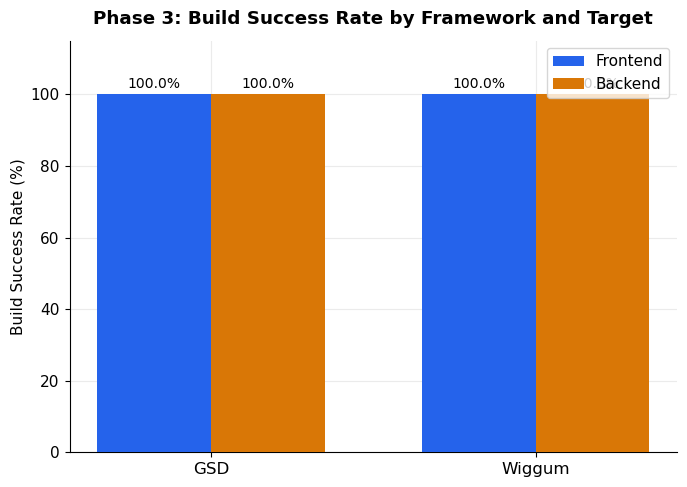

In [8]:
p3 = df[df['phase'] == 'Phase 3']

build_rates_p3 = (
    p3.groupby(['framework', 'target'])['buildSuccess']
    .mean()
    .mul(100)
    .unstack('target')
)

fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(len(build_rates_p3))
width = 0.35

bars_fe = ax.bar(x - width/2, build_rates_p3['frontend'], width,
                 label='Frontend', color=GSD_BLUE, zorder=3)

bars_be = ax.bar(x + width/2, build_rates_p3['backend'], width,
                 label='Backend', color=WIG_AMBER, zorder=3)

for bar in bars_fe:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)

for bar in bars_be:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(['GSD', 'Wiggum'], fontsize=12)
ax.set_ylabel('Build Success Rate (%)')
ax.set_ylim(0, 115)
ax.set_title('Phase 3: Build Success Rate by Framework and Target', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

Phase 2 and 3 show a ceiling result. GSD and Wiggum both reached 100% build success across frontend and backend targets, with no failures recorded in either phase.

At first glance this looks like it contradicts the intent of these tiers, which were specifically constructed to introduce reasoning demands the Phase 1 scaffold couldn't reach. But the two phases get to 100% for different reasons.

In Phase 2, the scaffold itself became considerably more demanding. The three-context React architecture, SQLite persistence replacing the in-memory cache, the typed error hierarchy, and the centralised middleware all raise the bar for correct reasoning. What didn't scale up to the same degree was file-coordination breadth. Each Phase 2 task is still fixing or extending a bounded piece of that scaffold rather than reasoning across the whole system at once. That containment is likely why both frameworks could produce a build that compiles and runs even where the underlying logic goes on to fail hidden tests or introduce quality regressions.

Phase 3 is the more telling case, since the two full-stack tasks require reasoning across frontend and backend simultaneously, and the profile-management task inherits directly from whatever the authentication task left behind. A clean build result here, under genuine cross-layer coordination and downstream dependency, is a stronger signal than Phase 2's. It suggests neither framework's instructional approach collapses at the point of structural integration, even though the two approaches, one persistence-oriented and gated, the other restart-and-rebuild, arrive at that build very differently.

The takeaway is the same one that this study's design anticipates. Build success is a binary, necessary but not sufficient signal, and once both frameworks clear it, the discriminating comparison has to happen in correctness and quality scores rather than in whether the code compiles at all. That's where the next set of results should carry the analysis.

## Phase 1 Hidden Pass Rate

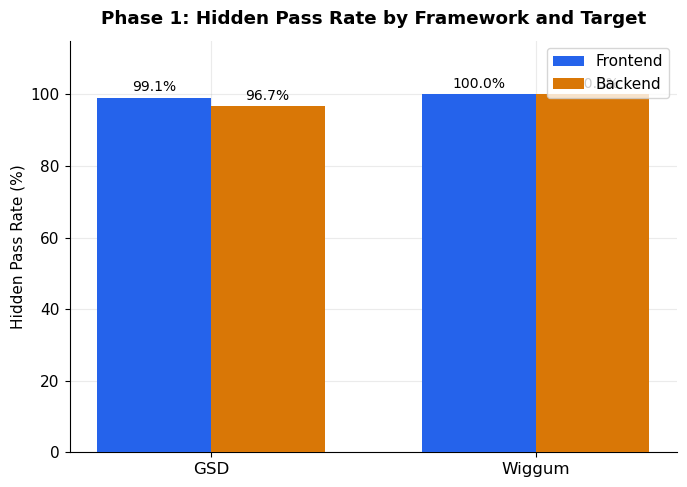

In [9]:
p1 = df[df['phase'] == 'Phase 1']

hidden_rates_p1 = (
    p1.groupby(['framework', 'target'])['hiddenPassRate']
    .mean()
    .mul(100)
    .unstack('target')
)

fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(len(hidden_rates_p1))
width = 0.35

bars_fe = ax.bar(x - width/2, hidden_rates_p1['frontend'], width,
                 label='Frontend', color=GSD_BLUE, zorder=3)

bars_be = ax.bar(x + width/2, hidden_rates_p1['backend'], width,
                 label='Backend', color=WIG_AMBER, zorder=3)

for bar in bars_fe:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)

for bar in bars_be:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(['GSD', 'Wiggum'], fontsize=12)
ax.set_ylabel('Hidden Pass Rate (%)')
ax.set_ylim(0, 115)
ax.set_title('Phase 1: Hidden Pass Rate by Framework and Target', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

Wiggum edges out GSD on both targets with a perfect 100% hidden pass rate on frontend and backend alike, against GSD's 99.1% frontend and 96.7% backend.

The frontend gap is negligible. 99.1% is close enough to ceiling that it likely reflects a single partially-failing run rather than a systematic weakness in GSD's frontend handling. The backend gap is a bit wider (3.3 points) and is worth flagging alongside the build result. GSD had already shown a small crack on the frontend build metric, and here it's the backend hidden-test metric that shows the larger deviation from Wiggum. Read together, this doesn't point to one target being GSD's weak spot consistently, it points more to isolated run-level misses than to a structural frontend/backend pattern.

More notable is what this does to the build-success narrative. Where GSD looked marginally more build-stable in Phase 1, that stability isn't converting into a functional-correctness edge. Wiggum matches or slightly beats GSD on the metric that actually reflects whether the code does what was asked. That's a useful early caution against treating build success as a proxy for correctness. A framework can produce a build that compiles cleanly and still trail on hidden-test performance, and vice versa.

Given Phase 1 was already established as too undemanding to meaningfully separate the two frameworks, a sub-1-point and a 3.3-point gap here both sit comfortably within what's expected from run-to-run noise at this tier rather than a real framework effect. Phase 2 and 3's harder reasoning tasks should be the more informative test of whether either framework holds a genuine correctness advantage.

## Phase 2 hidden pass rate

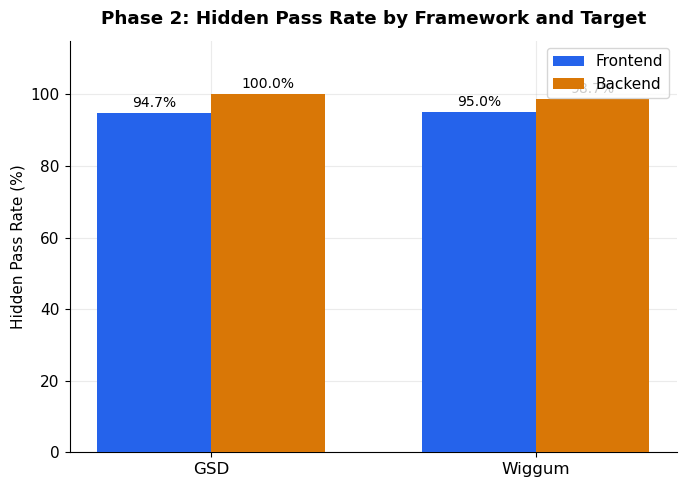

In [10]:
p2 = df[df['phase'] == 'Phase 2']

hidden_rates_p2 = (
    p2.groupby(['framework', 'target'])['hiddenPassRate']
    .mean()
    .mul(100)
    .unstack('target')
)

fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(len(hidden_rates_p2))
width = 0.35

bars_fe = ax.bar(x - width/2, hidden_rates_p2['frontend'], width,
                 label='Frontend', color=GSD_BLUE, zorder=3)

bars_be = ax.bar(x + width/2, hidden_rates_p2['backend'], width,
                 label='Backend', color=WIG_AMBER, zorder=3)

for bar in bars_fe:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)

for bar in bars_be:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(['GSD', 'Wiggum'], fontsize=12)
ax.set_ylabel('Hidden Pass Rate (%)')
ax.set_ylim(0, 115)
ax.set_title('Phase 2: Hidden Pass Rate by Framework and Target', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

The two frameworks stay close again, though not quite as tightly as Phase 1. GSD posted 94.7% frontend and 100% backend. Wiggum posted 95.5% frontend and 98.7% backend. Frontend is essentially a wash, a 0.3-point gap in Wiggum's favour, while backend now favours GSD by 1.3 points, with GSD reaching a clean ceiling.

What stands out most is the same inversion relative to expectation as before. Backend hidden pass rates are higher than frontend for both frameworks, even though Phase 2's backend additions (SQLite persistence, the typed error hierarchy, centralised middleware, per-IP rate limiting) were the heavier architectural lift of the two targets. That suggests the backend tasks' hidden tests, despite sitting on top of a more demanding scaffold, were evaluating more targeted, well-scoped behaviour, while the frontend tasks (context migration, derived-state correctness, focus management) may be exercising a kind of reasoning that's inherently harder to fully satisfy even when the underlying scaffold changes are smaller in scope.

GSD reaching 100% on backend here is the first point in the results so far where one framework clears a ceiling the other doesn't, and it's consistent with GSD's phase-gated verification being better suited to a target with more explicit, checkable structure (typed errors, centralised routing) to verify against. Frontend, where correctness likely hinges more on subtler state and interaction bugs, shows less separation between the two approaches.

Taken with Phase 1, the picture forming is that hidden pass rate isn't where these frameworks meaningfully diverge. Both are converging on a similar correctness ceiling per target, with GSD's backend result being the one exception so far. That keeps the analytical weight resting on the quality-score comparison to explain what's actually different about how the two frameworks get to similar correctness outcomes.

## Phase 3 hidden pass rate

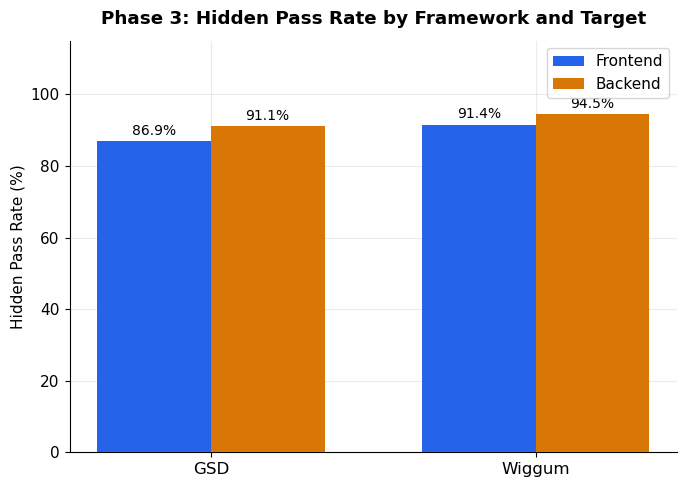

In [11]:
p3 = df[df['phase'] == 'Phase 3']

hidden_rates_p3 = (
    p3.groupby(['framework', 'target'])['hiddenPassRate']
    .mean()
    .mul(100)
    .unstack('target')
)

fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(len(hidden_rates_p3))
width = 0.35

bars_fe = ax.bar(x - width/2, hidden_rates_p3['frontend'], width,
                 label='Frontend', color=GSD_BLUE, zorder=3)

bars_be = ax.bar(x + width/2, hidden_rates_p3['backend'], width,
                 label='Backend', color=WIG_AMBER, zorder=3)

for bar in bars_fe:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)

for bar in bars_be:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(['GSD', 'Wiggum'], fontsize=12)
ax.set_ylabel('Hidden Pass Rate (%)')
ax.set_ylim(0, 115)
ax.set_title('Phase 3: Hidden Pass Rate by Framework and Target', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

Phase 3 is the first place hidden pass rates show a real, consistent gap rather than near-parity. Wiggum leads on both targets with 91.4% frontend vs GSD's 86.9% (a 4.5-point gap), and 94.5% backend vs GSD's 91.1% (a 3.4-point gap).

Both frameworks also drop relative to Phase 2 on both targets, not just frontend. GSD falls from 94.7% to 86.9% frontend and 100% to 91.1% backend. Wiggum falls from 95.5% to 91.4% frontend and 98.7% to 94.5% backend. That backend decline is worth flagging on its own, since backend had looked like the more resilient target through Phases 1 and 2. Phase 3's full-stack tasks change the nature of what's being tested. The profile-management task inherits directly from whatever the authentication task produced, so a backend hidden-test failure here can originate from a frontend-side reasoning gap in the prior task, or from the cross-layer coordination itself, instead of from a backend-specific weakness. That inherited-state design plausibly erodes both targets together, which is consistent with what's shown here.

The more interesting shift is that Wiggum now holds a real advantage not trading negligible margins with GSD. One plausible reading is that Phase 3's from-scratch, cross-layer coordination rewards Wiggum's approach of re-grounding entirely from the specification and current repo state at each restart, rather than carrying forward reasoning across a long single session. If GSD's earlier phase (auth) reasoning drifted or made an assumption that didn't hold, its persistent context may have propagated that assumption into the profile-management task rather than catching it fresh. That's consistent with the frameworks' designs rather than something these numbers alone can confirm, and it's the first phase where the gap is large enough to be worth taking as a signal.

So across the three phases, correctness moves from near-total convergence (Phase 1, Phase 2) to a clear and consistent Wiggum advantage under genuine cross-layer, inherited-state pressure (Phase 3). That's a meaningful finding on its own for RQ3, framework performance is not stable across task type, and the gap opens specifically where the tasks demand the kind of multi-step, dependent reasoning that Phase 1 and 2 couldn't reach. Whether this correctness edge is bought at a cost in code quality is covered in the latter sections.

# Task Overall Scores

## Phase 1 Frontend: Overall Score

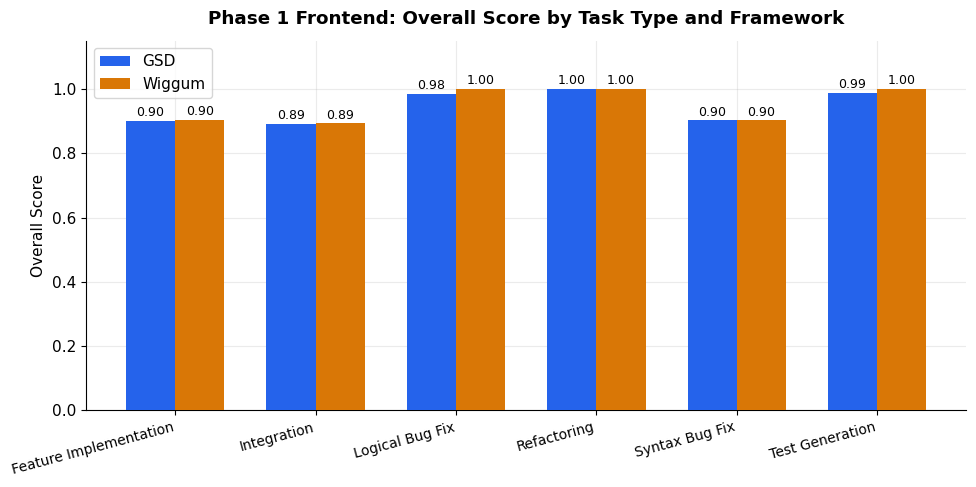

In [12]:
p1_fe = df[(df['phase'] == 'Phase 1') & (df['target'] == 'frontend')].copy()
p1_fe['taskType'] = p1_fe['taskId'].map(frontend_task_types)

overall_p1_fe = (
    p1_fe.groupby(['taskType', 'framework'])['overallScore']
    .mean()
    .unstack('framework')
)

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(overall_p1_fe))
width = 0.35

bars_gsd = ax.bar(x - width/2, overall_p1_fe['gsd'], width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, overall_p1_fe['wiggum'], width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(overall_p1_fe.index, fontsize=10, rotation=15, ha='right')
ax.set_ylabel('Overall Score')
ax.set_ylim(0, 1.15)
ax.set_title('Phase 1 Frontend: Overall Score by Task Type and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

The pattern here is convergence, even more so than in the hidden pass rate results. Four of the six task types produced literally identical scores between GSD and Wiggum. Feature implementation (0.90 vs 0.90), integration (0.89 vs 0.89), refactoring (1.00 vs 1.00), and syntax bug fixing (0.90 vs 0.90). The only two task types with any diivergence between the frameworks are logical bug fix (GSD 0.98, Wiggum 1.00) and test generation (GSD 0.99, Wiggum 1.00), gaps of 0.02 and 0.01 respectively, both marginally favouring Wiggum.

What's more informative than the framework comparison is the spread across task types itself. Scores range from 0.89 (integration) to a perfect 1.00 (refactoring), a wider variation than anything separating the two frameworks on any single task type. That points to task type, not framework design, being the stronger driver of overall score at this complexity tier, refactoring and logical bug fixes sit near ceiling for both approaches, while feature implementation and integration sit a full 0.10–0.11 lower regardless of which framework produced them.

This lines up with what the earlier Phase 1 results already suggested. At this tier the task suite doesn't demand enough divergent reasoning to meaningfully separate a specification-gated approach from a restart-based one. The four identical scores are a stronger version of that finding than near-identical scores would have been. It suggests both frameworks aren't just performing similarly, they may be converging on effectively the same solutions for a majority of task types here.

The two non-identical task types are worth holding onto as a thread, though, since Wiggum's slight edge on both logical bug fix and test generation is directionally consistent with a pattern where its fresh-context iteration handles narrowly-scoped, mechanically verifiable tasks better than GSD's gated approach, though at a 0.01–0.02 margin, this is not yet a claim the data can support strongly on its own. Whether that thread holds up is best judged against the Phase 1 backend results and then Phase 2, where task complexity gives the frameworks more room to actually diverge.

## Phase 1 Backend: Overall Score

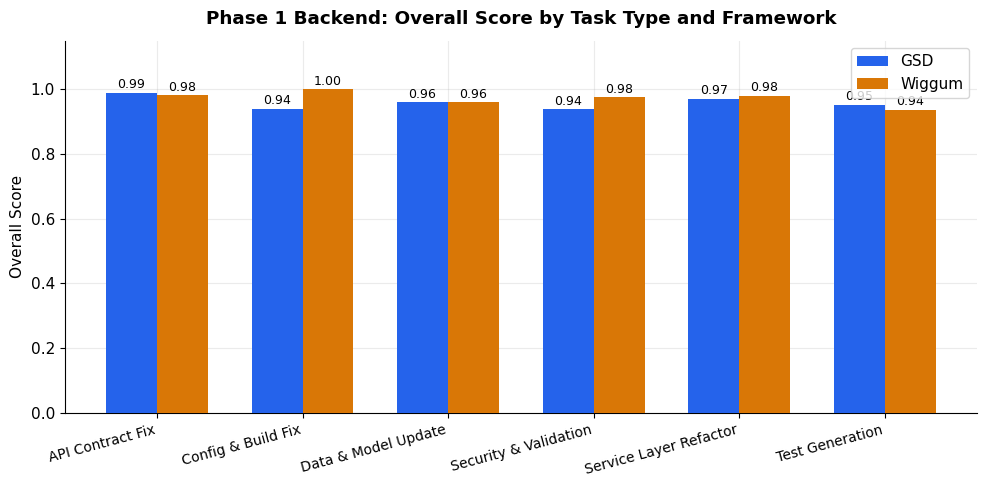

In [13]:
p1_be = df[(df['phase'] == 'Phase 1') & (df['target'] == 'backend')].copy()
p1_be['taskType'] = p1_be['taskId'].map(backend_task_types)

overall_p1_be = (
    p1_be.groupby(['taskType', 'framework'])['overallScore']
    .mean()
    .unstack('framework')
)

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(overall_p1_be))
width = 0.35

bars_gsd = ax.bar(x - width/2, overall_p1_be['gsd'], width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, overall_p1_be['wiggum'], width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(overall_p1_be.index, fontsize=10, rotation=15, ha='right')
ax.set_ylabel('Overall Score')
ax.set_ylim(0, 1.15)
ax.set_title('Phase 1 Backend: Overall Score by Task Type and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

Backend task types show a slightly wider spread than the near-total convergence seen on frontend, but the overall range is still tight. Everything falls between 0.94 and 1.00 for both frameworks, with no task type standing out as a shared weak point.

Wiggum holds the more consistent edge here. It leads on Config & Build Fix (1.00 vs 0.94, a 0.06 gap, the largest single difference in this set) and Security & Validation (0.98 vs 0.94, 0.04), and matches or narrowly beats GSD on Service Layer Refactoring (0.98 vs 0.97). GSD's only advantages are marginal. API Contract Fix (0.99 vs 0.98) and Test Generation (0.95 vs 0.94), each a 0.01 difference. Data & Model Update is an exact tie at 0.96.

The Config & Build Fix gap is the one worth sitting with. It's the largest differential in either Phase 1 target so far, and it runs counter to the pattern from the frontend results, where task-type variation dwarfed framework variation. Here, framework choice is producing a real, if still modest, effect on one specific task type. Build and configuration fixes are exactly the kind of narrowly-scoped, mechanically-checkable task where Wiggum's restart-and-rebuild cycle, re-deriving from the current repo state rather than carrying forward reasoning, may have an edge over a verification-gated approach that front-loads planning before touching config.

Security & Validation is the second-largest gap and points the same direction. That one is more consequential given the study's quality-scoring rationale weights security regressions most heavily of any dimension.

Taken with the frontend results, Phase 1 as a whole is starting to show a mild but consistent pattern. Where the two frameworks do diverge, even slightly, it tends to favour Wiggum rather than GSD.

## Phase 2 Frontend: Overall Score

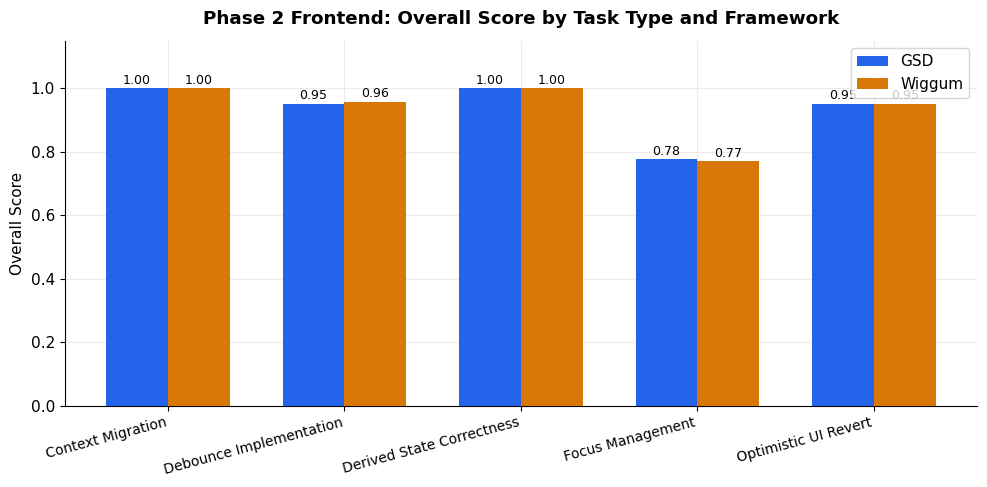

In [14]:
p2_fe = df[(df['phase'] == 'Phase 2') & (df['target'] == 'frontend')].copy()
p2_fe['taskType'] = p2_fe['taskId'].map(frontend_task_types_p2)

overall_p2_fe = (
    p2_fe.groupby(['taskType', 'framework'])['overallScore']
    .mean()
    .unstack('framework')
)

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(overall_p2_fe))
width = 0.35

bars_gsd = ax.bar(x - width/2, overall_p2_fe['gsd'], width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, overall_p2_fe['wiggum'], width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(overall_p2_fe.index, fontsize=10, rotation=15, ha='right')
ax.set_ylabel('Overall Score')
ax.set_ylim(0, 1.15)
ax.set_title('Phase 2 Frontend: Overall Score by Task Type and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

## Phase 2 Backend: Overall Score

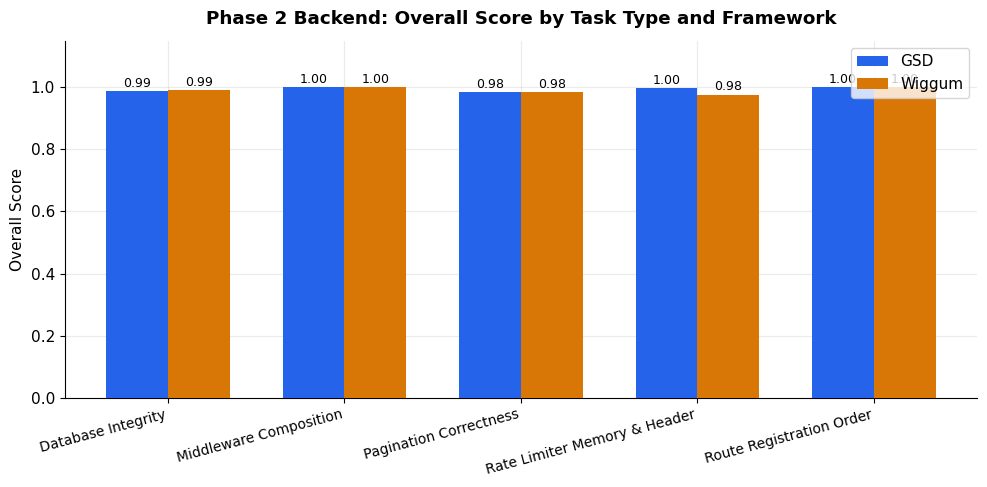

In [15]:
p2_be = df[(df['phase'] == 'Phase 2') & (df['target'] == 'backend')].copy()
p2_be['taskType'] = p2_be['taskId'].map(backend_task_types_p2)

overall_p2_be = (
    p2_be.groupby(['taskType', 'framework'])['overallScore']
    .mean()
    .unstack('framework')
)

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(overall_p2_be))
width = 0.35

bars_gsd = ax.bar(x - width/2, overall_p2_be['gsd'], width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, overall_p2_be['wiggum'], width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(overall_p2_be.index, fontsize=10, rotation=15, ha='right')
ax.set_ylabel('Overall Score')
ax.set_ylim(0, 1.15)
ax.set_title('Phase 2 Backend: Overall Score by Task Type and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

Phase 2 continues the convergence pattern seen through most of Phase 1, on both targets.

On frontend, three of five task types are identical between frameworks. Context Migration (1.00/1.00), Derived State Correctness (1.00/1.00), and Optimistic UI Revert (0.95/0.95). The other two show only marginal separation, Debounce Implementation slightly favours Wiggum (0.96 vs 0.95), while Focus Management slightly favours GSD (0.78 vs 0.77). Focus Management is also the clear low point for both frameworks, sitting a full 0.17–0.22 below every other frontend task type. That task involves portal rendering and full keyboard/focus-trap accessibility handling, a qualitatively different, more interaction-behaviour-driven kind of correctness than the state-and-data-flow reasoning the other four tasks demand, and both frameworks appear to find it meaningfully harder regardless of instructional structure.

Backend is even tighter. Database Integrity (0.99/0.99), Middleware Composition (1.00/1.00), Pagination Correctness (0.98/0.98), and Route Registration Order (1.00/1.00) are all exact ties. The single point of separation is Rate Limiter Memory and Header, where GSD reaches 1.00 against Wiggum's 0.98, a small gap, but notable for being GSD's only outright win in this entire Phase 2 set. Rate limiting with sliding-window memory management and correct retry-after headers is a stateful-middleware task with a fairly explicit, checkable correctness contract, which is consistent with GSD's verification-gated approach doing slightly better where success criteria are more precisely specifiable up front.

So the overall shape of Phase 2 is in near-total agreement between frameworks on most task types, one shared weak point (Focus Management) that looks like a task-difficulty effect rather than a framework effect, and one isolated GSD edge (Rate Limiter) that's consistent with its design philosophy but too small on its own to call a trend. This reinforces what Phase 1 already suggested. Task type is doing far more work than framework choice in explaining score variation at this complexity level. The real test of whether framework structure matters is likely to show up more in Phase 3, and in the quality-score dimensions rather than the overall/correctness numbers alone.

## Phase 3: Overall Score

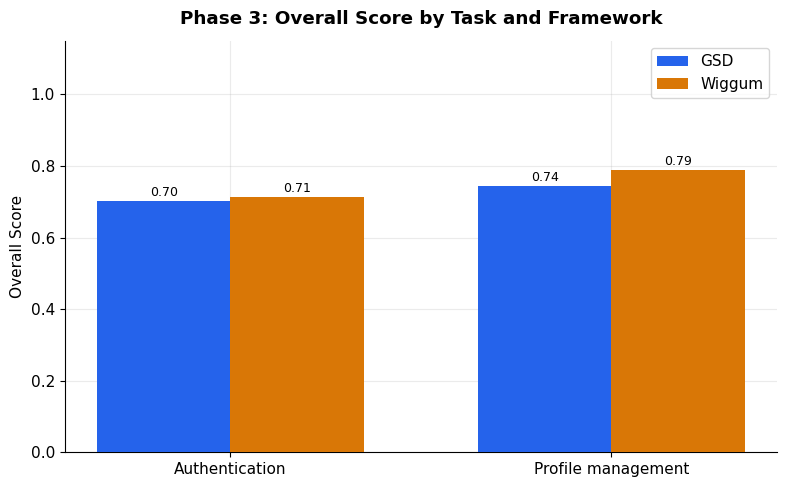

In [16]:
p3 = df[df['phase'] == 'Phase 3'].copy()
p3['taskType'] = p3['taskId'].map(phase3_task_types)

overall_p3 = (
    p3.groupby(['taskType', 'framework'])['overallScore']
    .mean()
    .unstack('framework')
)

fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(overall_p3))
width = 0.35

bars_gsd = ax.bar(x - width/2, overall_p3['gsd'], width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, overall_p3['wiggum'], width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)
    
for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(overall_p3.index, fontsize=11)
ax.set_ylabel('Overall Score')
ax.set_ylim(0, 1.15)
ax.set_title('Phase 3: Overall Score by Task and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

Phase 3 produces the lowest overall scores anywhere in the study, for both frameworks. A clear signal that full-stack, cross-layer, from-scratch implementation is the hardest condition either framework has faced. GSD scores 0.70 on Authentication and 0.74 on Profile Management. Wiggum scores 0.71 and 0.79 respectively.

Authentication is essentially tied (a 0.01 gap, within noise). Profile Management is where the gap opens up. Wiggum leads by 0.05, its largest margin of advantage across any task type in the entire study so far. That's a meaningful number to sit with given Profile Management is the task that inherits state directly from whatever Authentication produced, so this gap isn't purely about Profile Management in isolation, it may partly reflect how well each framework's authentication output set up the second task to succeed.

Both frameworks also score higher on Profile Management than on Authentication, despite Profile Management carrying the added burden of building on prior output. That's a bit counter to what we'd expect if inherited state were purely a liability. It suggests Authentication (user registration, login, password hashing, JWT and API contract design end-to-end) is simply the harder task in its own right, likely because it demands more genuinely novel architectural decisions than Profile Management's protected page with inline edits, which can build more directly off patterns Authentication already established.

# 4.2. Task Success Rates

# Task Correctness Scores

## Phase 1 frontend correctness score

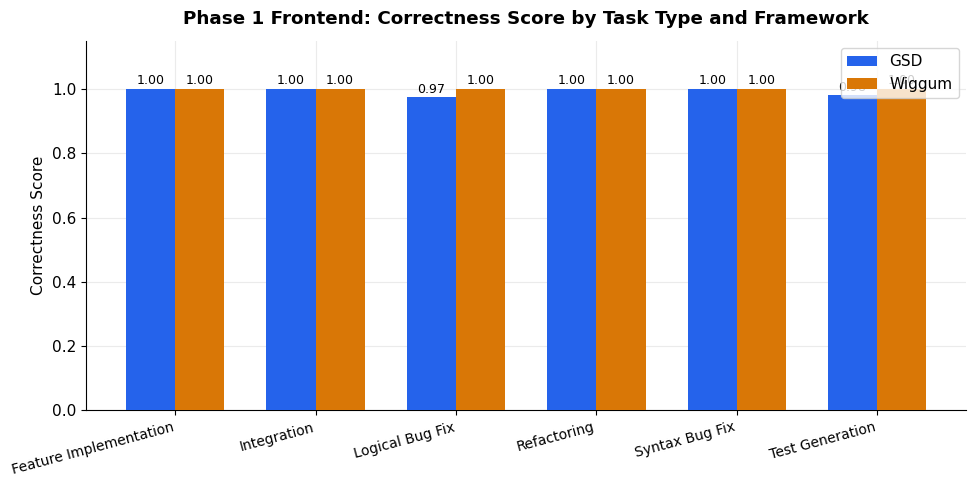

In [17]:
p1_fe = df[(df['phase'] == 'Phase 1') & (df['target'] == 'frontend')].copy()
p1_fe['taskType'] = p1_fe['taskId'].map(frontend_task_types)

correctness_p1_fe = (
    p1_fe.groupby(['taskType', 'framework'])['correctnessScore']
    .mean()
    .unstack('framework')
)

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(correctness_p1_fe))
width = 0.35

bars_gsd = ax.bar(x - width/2, correctness_p1_fe['gsd'], width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, correctness_p1_fe['wiggum'], width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(correctness_p1_fe.index, fontsize=10, rotation=15, ha='right')
ax.set_ylabel('Correctness Score')
ax.set_ylim(0, 1.15)
ax.set_title('Phase 1 Frontend: Correctness Score by Task Type and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

Correctness is at or near ceiling for both frameworks across nearly every task type. GSD scores a perfect 1.00 on five of six task types (Feature Implementation, Integration, Refactoring, Syntax Bug Fix) and dips only on Logical Bug Fix (0.97) and Test Generation (0.99). Wiggum goes one better, hitting 1.00 on five task types and matching GSD's 0.99 on Test Generation, with its only distinguishing feature being a perfect 1.00 on Logical Bug Fix where GSD sits at 0.97.

The single meaningful gap here is Logical Bug Fix. A 0.03 edge for Wiggum. That's a small margin in absolute terms, but logical bug fixing is a task type with a fairly determinate notion of "correct", either the fix resolves the injected logical error against the hidden tests or it doesn't, so a gap here is more likely to reflect a genuine, if modest, difference in how reliably each framework converges on the right fix than it is to reflect task ambiguity.

What this section clarifies is where the overall-score variation from the previous comparison is actually coming from. Feature Implementation, Integration, and Syntax Bug Fix all showed overall scores around 0.89–0.90 for both frameworks despite both hitting perfect 1.00 correctness here. Since overall score is a 60/40 blend of correctness and quality, and correctness can't explain those dips when it's sitting at ceiling, that gap has to be coming from the quality dimension, regressions in security, type discipline, coupling, complexity, or duplication picked up during those tasks. Refactoring, by contrast, hit 1.00 on both overall score and correctness for both frameworks, implying it's the one task type where neither framework introduced any quality regression at all.

So, correctness alone doesn't explain most of what's driving overall-score differences at this tier, either between frameworks or across task types. The quality-score breakdown is where the real explanatory work is going to happen, and it's worth checking whether Wiggum's marginal correctness edges (Logical Bug Fix here, plus the Test Generation and other slight leads seen in the overall scores) are being reinforced or offset once quality penalties are factored in.

## Phase 1 backend correctness score

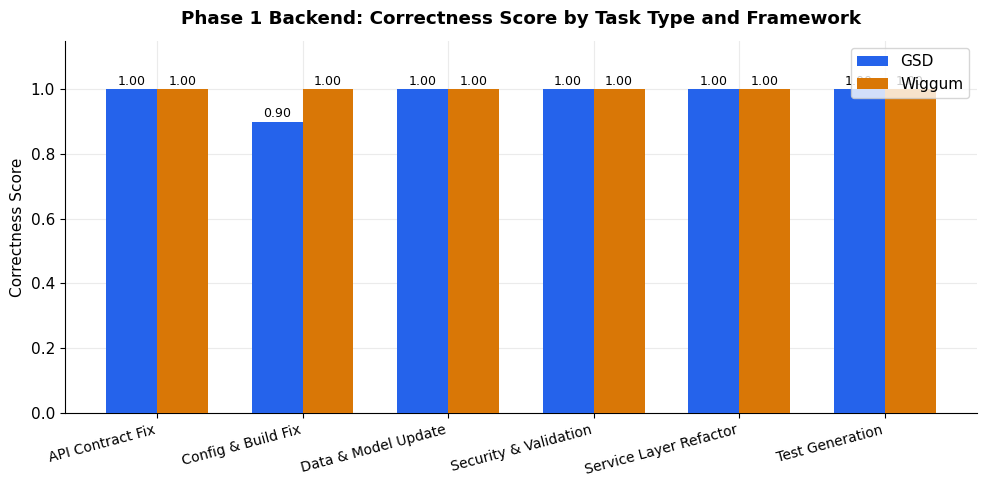

In [18]:
p1_be = df[(df['phase'] == 'Phase 1') & (df['target'] == 'backend')].copy()
p1_be['taskType'] = p1_be['taskId'].map(backend_task_types)

correctness_p1_be = (
    p1_be.groupby(['taskType', 'framework'])['correctnessScore']
    .mean()
    .unstack('framework')
)

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(correctness_p1_be))
width = 0.35

bars_gsd = ax.bar(x - width/2, correctness_p1_be['gsd'], width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, correctness_p1_be['wiggum'], width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(correctness_p1_be.index, fontsize=10, rotation=15, ha='right')
ax.set_ylabel('Correctness Score')
ax.set_ylim(0, 1.15)
ax.set_title('Phase 1 Backend: Correctness Score by Task Type and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

Correctness converges almost completely here. Both frameworks hit a perfect 1.00 on five of six task types, API Contract Fix, Data & Model Update, Security & Validation, Service Layer Refactoring, and Test Generation. The single exception is Config & Build Fix, where GSD drops to 0.90 against Wiggum's perfect 1.00, a 0.10 gap, and the largest correctness difference seen between the two frameworks in Phase 1 on either target.

That gap is useful because it cleanly explains something from the overall-score comparison. GSD's Config & Build Fix overall score (0.94) trailed Wiggum's (1.00) by 0.06, and since correctness alone accounts for a 0.10 gap once weighted at 60%, that's consistent with GSD's quality score on this task type being just as strong as Wiggum's, the overall-score gap here is a pure correctness story, not a quality one. That's a different shape from most of what's shown up so far, where overall-score differences have tended to trace back to the quality dimension rather than correctness.

Everywhere else, since correctness is tied at 1.00 for both frameworks, any overall-score differences seen on API Contract Fix, Security & Validation, Service Layer Refactoring, and Test Generation must be coming entirely from quality-score regressions rather than functional correctness. Security & Validation is the one worth flagging in particular. GSD's overall score there (0.94) trailed Wiggum's (0.98) despite tied correctness, which implies GSD picked up more quality penalties on a task type where the study's scoring model weights security regressions most heavily of any dimension.

So Phase 1 backend correctness tells a narrower story than Phase 1 backend overall score did. The frameworks are functionally near-identical everywhere except Config & Build Fix, where GSD underperforms outright. The remaining variation across task types is a quality-score question, not a correctness one, reinforcing that the quality breakdown is where the more decisive framework comparison is going to happen.

## Phase 2 frontend correctness score

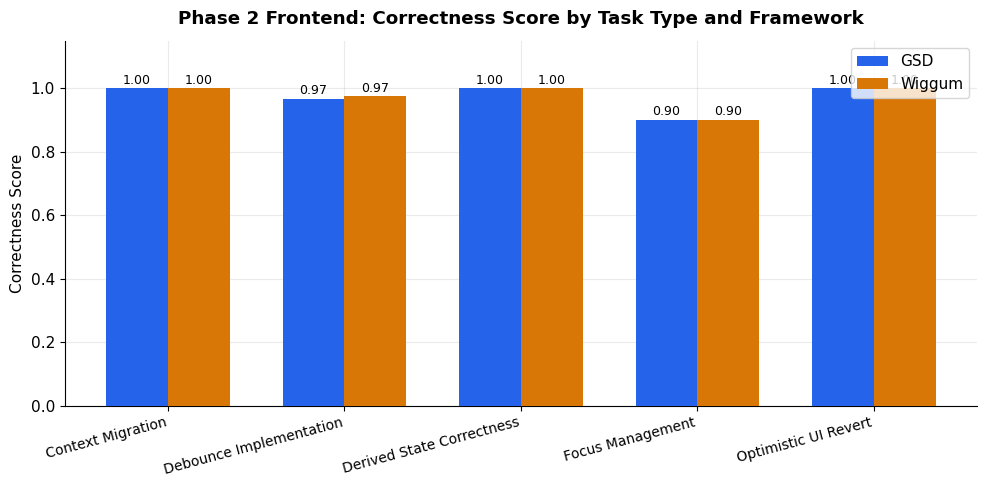

In [19]:
p2_fe = df[(df['phase'] == 'Phase 2') & (df['target'] == 'frontend')].copy()
p2_fe['taskType'] = p2_fe['taskId'].map(frontend_task_types_p2)

correctness_p2_fe = (
    p2_fe.groupby(['taskType', 'framework'])['correctnessScore']
    .mean()
    .unstack('framework')
)

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(correctness_p2_fe))
width = 0.35

bars_gsd = ax.bar(x - width/2, correctness_p2_fe['gsd'], width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, correctness_p2_fe['wiggum'], width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(correctness_p2_fe.index, fontsize=10, rotation=15, ha='right')
ax.set_ylabel('Correctness Score')
ax.set_ylim(0, 1.15)
ax.set_title('Phase 2 Frontend: Correctness Score by Task Type and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

## Phase 2 backend correctness score

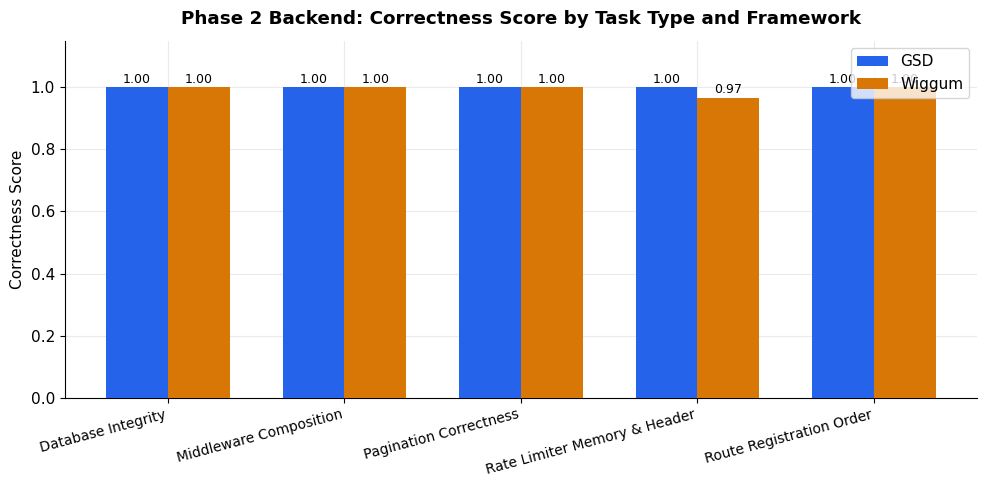

In [20]:
p2_be = df[(df['phase'] == 'Phase 2') & (df['target'] == 'backend')].copy()
p2_be['taskType'] = p2_be['taskId'].map(backend_task_types_p2)

correctness_p2_be = (
    p2_be.groupby(['taskType', 'framework'])['correctnessScore']
    .mean()
    .unstack('framework')
)

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(correctness_p2_be))
width = 0.35

bars_gsd = ax.bar(x - width/2, correctness_p2_be['gsd'], width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, correctness_p2_be['wiggum'], width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(correctness_p2_be.index, fontsize=10, rotation=15, ha='right')
ax.set_ylabel('Correctness Score')
ax.set_ylim(0, 1.15)
ax.set_title('Phase 2 Backend: Correctness Score by Task Type and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

Frontend shows total convergence this time, every one of the five task types is an exact tie between GSD and Wiggum. Context Migration (1.00/1.00), Debounce Implementation (0.97/0.97), Derived State Correctness (1.00/1.00), Focus Management (0.90/0.90), and Optimistic UI Revert (1.00/1.00). There is no framework-level correctness gap anywhere on frontend at this tier.

That's a useful reference point against the overall scores seen earlier, where Debounce Implementation and Focus Management each showed a small 0.01 overall-score gap despite identical correctness here. With correctness tied in both cases, those gaps have to be sitting entirely in the quality dimension, and they run in opposite directions (Wiggum ahead on Debounce, GSD ahead on Focus Management), which is a reminder that neither framework holds a consistent quality edge across frontend task types at this tier; it varies by task.

Backend is almost as uniform. Database Integrity, Middleware Composition, Pagination Correctness, and Route Registration Order are all perfect 1.00/1.00 ties. The one exception is Rate Limiter Memory and Header, where GSD holds a perfect 1.00 against Wiggum's 0.97, a 0.03 gap. This is the same task type that showed a small overall-score gap earlier (1.00 vs 0.98), and here the arithmetic lines up cleanly. With GSD's correctness advantage weighted at 60%, it accounts for essentially the entire overall-score difference, meaning quality regressions aren't really contributing to GSD's edge on this task, it's a straightforward correctness win. That's consistent with Rate Limiter being a stateful, timing-sensitive task (sliding-window memory, retry-after headers) where GSD's upfront verification against explicit success criteria plausibly catches an edge case that Wiggum's fresh-context restarts miss.

Taken together, Phase 2 correctness reinforces what's been building across Phase 1. Functional correctness is stable across frameworks at this complexity tier, with Focus Management again standing out as a shared low point (0.90 for both) that looks like a genuine task-difficulty ceiling instead of a framework weakness. The one real correctness separation, Rate Limiter, is narrow but is GSD's clearest, least ambiguous win in the study so far. Everything else that differentiates the frameworks at this tier is, once again, going to come down to the quality-score breakdown rather than whether the tasks were completed correctly.

## Phase 3 correctness score

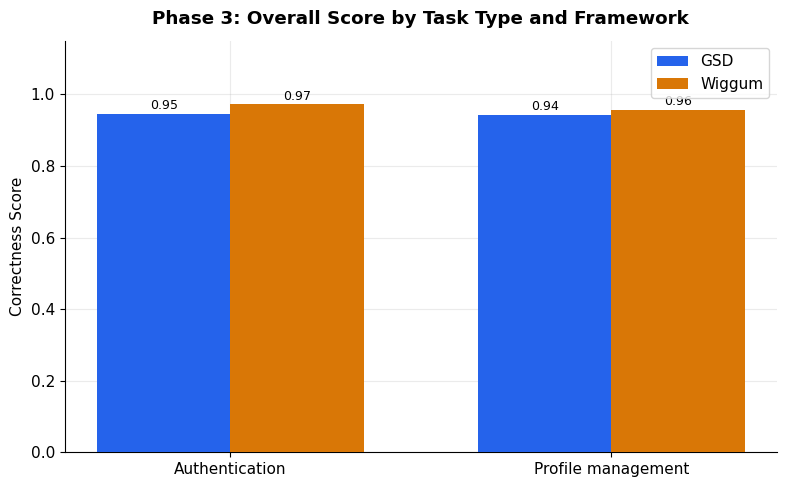

In [21]:
p3 = df[df['phase'] == 'Phase 3'].copy()
p3['taskType'] = p3['taskId'].map(phase3_task_types)

overall_p3 = (
    p3.groupby(['taskType', 'framework'])['correctnessScore']
    .mean()
    .unstack('framework')
)

fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(overall_p3))
width = 0.35

bars_gsd = ax.bar(x - width/2, overall_p3['gsd'], width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, overall_p3['wiggum'], width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)
    
for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(overall_p3.index, fontsize=11)
ax.set_ylabel('Correctness Score')
ax.set_ylim(0, 1.15)
ax.set_title('Phase 3: Overall Score by Task Type and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

Correctness stays close but consistently favours Wiggum here, unlike the mixed or negligible gaps seen at earlier tiers. Wiggum leads on both Authentication (0.97 vs 0.95) and Profile Management (0.96 vs 0.94), a 0.02 gap in each case. It's a modest margin per task, but the direction is now uniform across both Phase 3 task types, which stands apart from Phase 1 and 2 where any correctness differences were either tied or split between the two frameworks depending on task type.

What's more striking, though, is what these correctness scores imply about the quality dimension once set against the overall scores from earlier. On Authentication, the overall-score gap between the frameworks (0.70 vs 0.71) is small and tracks almost exactly with what the 0.02 correctness gap alone would produce at a 60% weighting. This means that quality regressions were roughly comparable for both frameworks on that task. Profile Management tells a different story. The overall-score gap there (0.74 vs 0.79, a full 0.05) is considerably larger than the 0.02 correctness gap can account for on its own, which means Wiggum's advantage on Profile Management isn't just a correctness story, it also produced meaningfully fewer quality regressions than GSD on that specific task.

That's a notable pattern for RQ2 and RQ3 together. On the hardest, most architecturally open-ended tier in the study, Wiggum isn't just matching or slightly beating GSD on whether the code works, it appears to be doing so while introducing less quality damage on at least one of the two tasks. Given Phase 3 is exactly the condition designed to stress-test each framework's reasoning under minimal existing structure to lean on, this is the first point in the results where correctness and quality seem to be moving in the same direction instead of trading off against each other, and it's worth confirming directly once the quality-score deltas for Phase 3 come through, since that's where this inference is currently resting on back-calculation not the reported figures themselves.

## Phase 1 frontend quality score

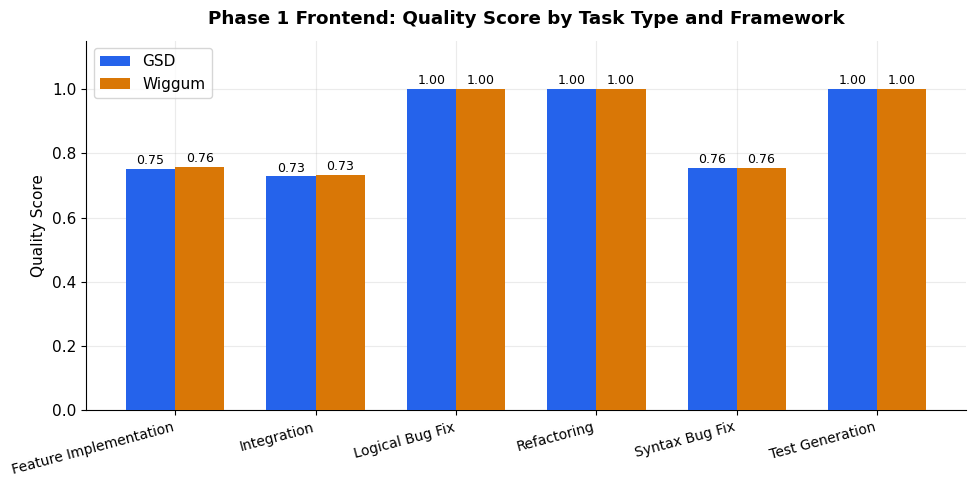

In [22]:
quality_p1_fe = (
    p1_fe.groupby(['taskType', 'framework'])['qualityScore']
    .mean()
    .unstack('framework')
)

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(quality_p1_fe))
width = 0.35

bars_gsd = ax.bar(x - width/2, quality_p1_fe['gsd'], width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, quality_p1_fe['wiggum'], width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(quality_p1_fe.index, fontsize=10, rotation=15, ha='right')
ax.set_ylabel('Quality Score')
ax.set_ylim(0, 1.15)
ax.set_title('Phase 1 Frontend: Quality Score by Task Type and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

Contrary to what the correctness results implied about where framework differentiation might surface, the quality scores here show almost total convergence too. GSD and Wiggum are within 0.01 of each other on every task type. Feature implementation (0.75 vs 0.76), integration (0.73 vs 0.73, an exact tie), logical bug fix (1.00 vs 1.00), refactoring (1.00 vs 1.00), syntax bug fixing (0.76 vs 0.76), and test generation (1.00 vs 1.00). The only non-zero gap in the entire set is a single point on feature implementation, which is well within what is expected from run-to-run variation rather than a framework effect.

This is a notable finding in its own right, because it resolves an open question from the earlier sections. The overall-score gaps that showed up on Logical Bug Fix and Test Generation looked, at the time, like they might trace back to quality-score differences given correctness was tied or near-tied on both. That's not what's happening, quality is also tied at 1.00 for both frameworks on both of those task types. The small overall-score differences observed earlier are better explained by the modest correctness gap on Logical Bug Fix (where Wiggum led by 0.03) and by rounding noise on Test Generation, rather than by any underlying quality regression pattern.

What this really shows is that Feature Implementation, Integration, and Syntax Bug Fix are the three task types carrying most of the quality penalty at this tier for both frameworks alike, dropping from a perfect 1.00 down into the 0.73–0.76 range, while Logical Bug Fix, Refactoring, and Test Generation come through with no quality regressions at all. That's a task-type effect, not a framework effect. Whatever is producing quality penalties on feature-building and integration work (likely complexity, coupling, or duplication regressions given those are the more open-ended task types) is affecting both frameworks in essentially the same way.

So Phase 1 frontend, taken as a whole across overall score, correctness, and quality, tells a fairly clean story. GSD and Wiggum are producing near-equivalent outcomes by every measure at this complexity tier, with task type doing far more to explain the variation than framework design does. That reinforces the case for why Phase 2 and 3 were necessary, Phase 1 alone would support very little in the way of a framework-level conclusion.

## Phase 1 backend quality score

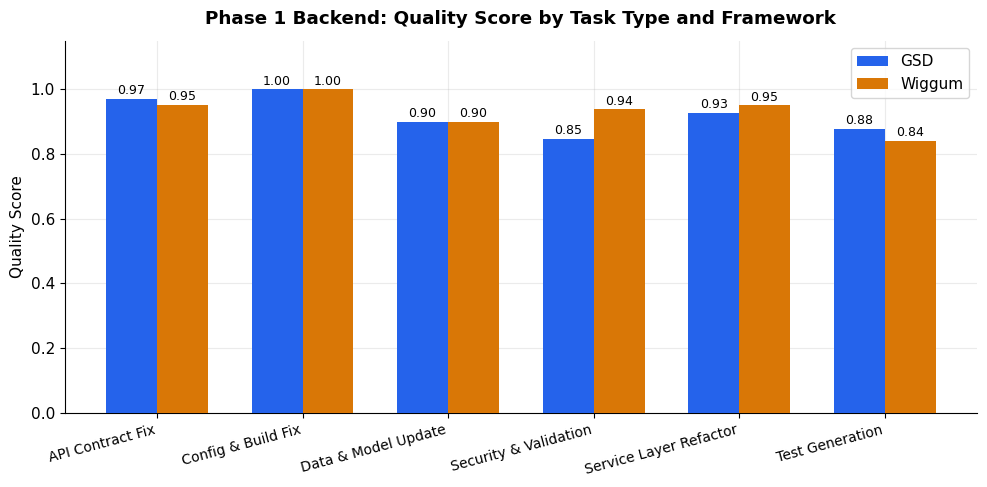

In [23]:
quality_p1_be = (
    p1_be.groupby(['taskType', 'framework'])['qualityScore']
    .mean()
    .unstack('framework')
)

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(quality_p1_be))
width = 0.35

bars_gsd = ax.bar(x - width/2, quality_p1_be['gsd'], width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, quality_p1_be['wiggum'], width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(quality_p1_be.index, fontsize=10, rotation=15, ha='right')
ax.set_ylabel('Quality Score')
ax.set_ylim(0, 1.15)
ax.set_title('Phase 1 Backend: Quality Score by Task Type and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

## Explanation

Backend quality shows more separation than backend correctness did, though nothing dramatic. GSD leads on API Contract Fix (0.97 vs 0.95) and Test Generation (0.88 vs 0.84), while Wiggum leads on Service Layer Refactoring (0.95 vs 0.93) and, most notably, Security & Validation (0.94 vs 0.85). Data & Model Update (0.90 vs 0.90) and Config & Build Fix (1.00 vs 1.00) are exact ties.

The Security & Validation gap is the one to pay attention to. At 0.09, it's the largest quality-score gap seen anywhere in the study so far, and it sits in the one scoring dimension the study weights most heavily, security findings carry the steepest per-instance penalty (-0.20) of any quality metric. Both frameworks reached identical, perfect correctness on this task type, so this gap is not about whether the fix worked. It's specifically about GSD introducing more security-relevant regressions (missing input validation, unsafe patterns, or similar) while getting there. That cuts against an assumption we might reasonably make going in, that GSD's upfront specification and verification gates would make it the more conservative, security-safe framework. Here, at least on this task type, it's the opposite.

Config & Build Fix is the other point worth holding onto, precisely because quality is tied at a perfect 1.00 for both frameworks despite GSD trailing badly on correctness for this task type (0.90 vs 1.00, as seen in the correctness breakdown). That combination says something specific. When GSD does produce a working config/build fix, it's exactly as clean as Wiggum's, it isn't failing more often because it's cutting structural corners, it's genuinely failing to resolve the task correctly at a higher rate. That's a meaningfully different failure mode than the Security & Validation case, where GSD succeeds functionally but does more collateral quality damage along the way.

The remaining gaps (API Contract Fix, Service Layer Refactoring, Test Generation) are all small, 0.02–0.04, and roughly split in direction between the frameworks, not enough on their own to support a directional claim about which framework is generally "higher quality" on backend work. The Security & Validation finding is the standout from this set and is worth carrying forward explicitly into the Phase 2 and 3 quality comparisons, since a security-specific quality gap of this size, in this particular direction, is the kind of result the study's whole scoring design was built to surface.

## Phase 2 frontend quality scores

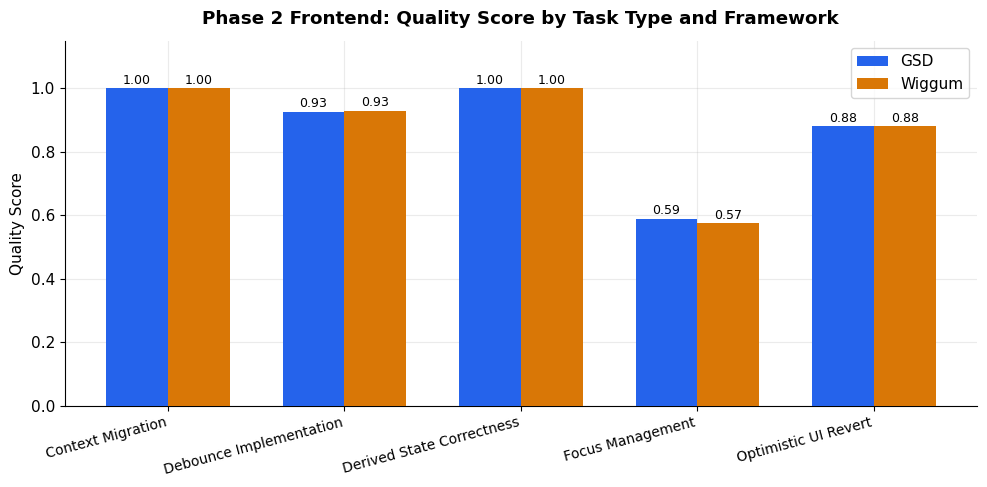

In [24]:
quality_p2_fe = (
    p2_fe.groupby(['taskType', 'framework'])['qualityScore']
    .mean()
    .unstack('framework')
)

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(quality_p2_fe))
width = 0.35

bars_gsd = ax.bar(x - width/2, quality_p2_fe['gsd'], width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, quality_p2_fe['wiggum'], width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(quality_p2_fe.index, fontsize=10, rotation=15, ha='right')
ax.set_ylabel('Quality Score')
ax.set_ylim(0, 1.15)
ax.set_title('Phase 2 Frontend: Quality Score by Task Type and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

## Phase 2 backend quality scores

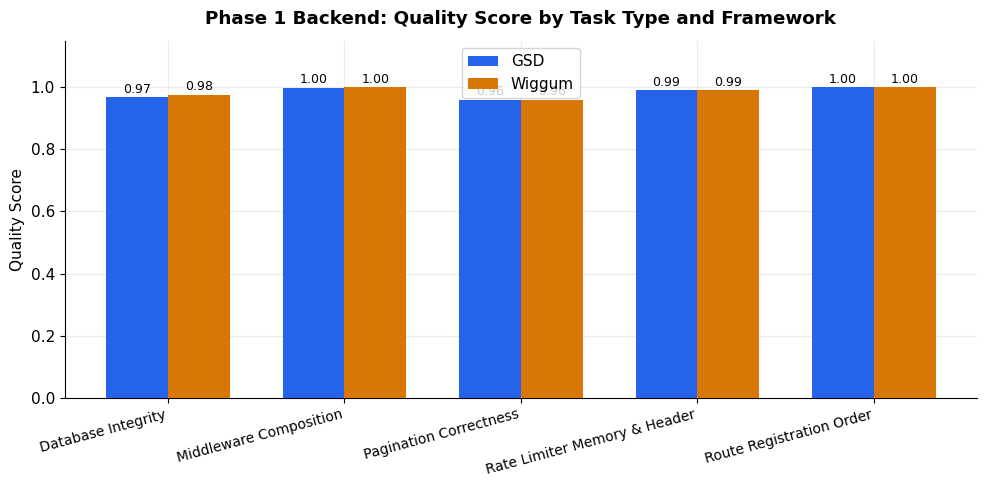

In [25]:
quality_p2_be = (
    p2_be.groupby(['taskType', 'framework'])['qualityScore']
    .mean()
    .unstack('framework')
)

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(quality_p2_be))
width = 0.35

bars_gsd = ax.bar(x - width/2, quality_p2_be['gsd'], width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, quality_p2_be['wiggum'], width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(quality_p2_be.index, fontsize=10, rotation=15, ha='right')
ax.set_ylabel('Quality Score')
ax.set_ylim(0, 1.15)
ax.set_title('Phase 1 Backend: Quality Score by Task Type and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

Quality continues the same convergence pattern seen in Phase 2 correctness, across both targets. On frontend, three task types are exact ties, Context Migration (1.00/1.00), Derived State Correctness (1.00/1.00), and Optimistic UI Revert (0.88/0.88). Debounce Implementation is also tied (0.93/0.93). The only separation is on Focus Management, where GSD edges ahead slightly (0.59 vs 0.57) with a 0.02 gap that's small enough to sit within normal run variance rather than indicate a framework effect.

Focus Management is, once again, the clear quality floor for both frameworks, 0.57–0.59 against 0.88–1.00 everywhere else on frontend. That's consistent with the correctness picture from this same task type and reinforces that whatever makes Focus Management hard (the portal-rendering and full keyboard/accessibility handling it requires) is producing quality regressions as well as correctness misses, for both frameworks alike. This looks like a genuine task-difficulty effect rather than something either framework's instructional structure is failing to manage.

Backend is essentially uniform with Middleware Composition (1.00/1.00) and Route Registration Order (1.00/1.00) are perfect ties, Pagination Correctness (0.96/0.96) and Rate Limiter Memory and Header (0.99/0.99) are also tied, and the only gap is Database Integrity, where Wiggum is marginally ahead (0.98 vs 0.97) with a 0.01 difference, negligible on its own.

Taken as a whole, Phase 2 quality doesn't show the kind of standout gap that Phase 1's Security & Validation result did, nothing here approaches that magnitude. That's a meaningful negative finding, whatever gave Wiggum its clear quality edge on backend security work in Phase 1 doesn't repeat itself at this complexity tier, at least not on these five backend task types. At Phase 2, task type (specifically Focus Management's difficulty) is doing essentially all of the explanatory work, and framework choice is contributing almost nothing to the variation in either correctness or quality. Whether that changes again under Phase 3's full-stack conditions, where the Phase 3 overall scores already hinted at a real Wiggum quality advantage on Profile Management, is the next thing to confirm.

## Phase 3 quality score

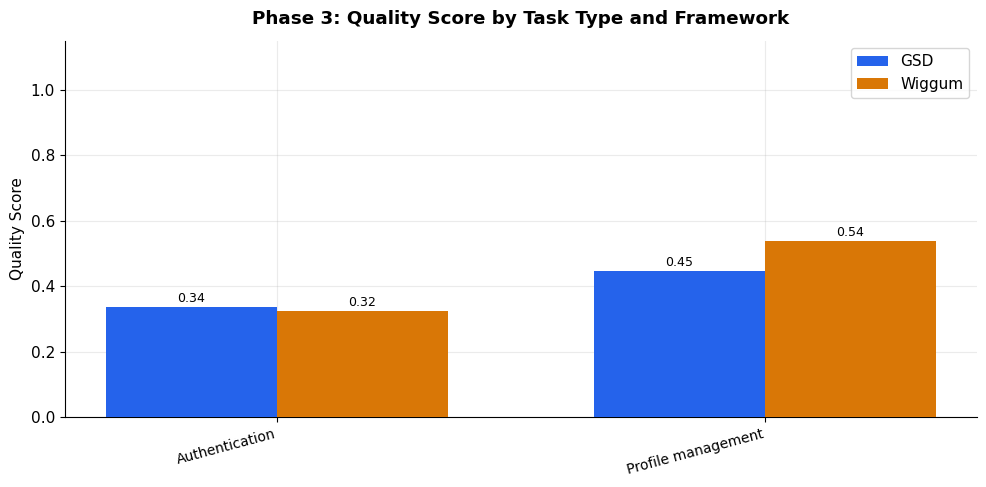

In [26]:
quality_p3 = (
    p3.groupby(['taskType', 'framework'])['qualityScore']
    .mean()
    .unstack('framework')
)

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(quality_p3))
width = 0.35

bars_gsd = ax.bar(x - width/2, quality_p3['gsd'], width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, quality_p3['wiggum'], width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(quality_p3.index, fontsize=10, rotation=15, ha='right')
ax.set_ylabel('Quality Score')
ax.set_ylim(0, 1.15)
ax.set_title('Phase 3: Quality Score by Task Type and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

Phase 3 produces the lowest quality scores anywhere in the study, by a wide margin, for both frameworks. Authentication comes in at 0.34 (GSD) and 0.32 (Wiggum). Profile Management at 0.45 (GSD) and 0.54 (Wiggum). Every other task type across Phase 1 and 2 sat at 0.73 or higher, Phase 3 is roughly half that or worse. This is the clearest evidence in the study that greenfield, cross-layer implementation from scratch is a fundamentally different and harder condition for quality preservation than the modify-and-fix tasks that make up Phases 1 and 2, for both frameworks alike.

Authentication is essentially tied (0.34 vs 0.32, a 0.02 gap, negligible). Profile Management is where the frameworks separate meaningfully. Wiggum leads by 0.09, its largest quality-score advantage anywhere in the study except for GSD's Security & Validation deficit back in Phase 1. Combined with Wiggum's small correctness edge on the same task, this is what's driving Wiggum's clear overall-score lead on Profile Management seen earlier, both dimensions are pulling in the same direction rather than trading off against each other

The Authentication to Profile Management improvement for both frameworks is worth noting on its own. Profile Management inherits directly from whatever Authentication produced, so a compounding-errors pattern would predict quality getting worse, not better, moving from the first task to the second. Instead both frameworks recover, and Wiggum recovers considerably more, climbing from 0.32 to 0.54 versus GSD's more modest 0.34 to 0.45. That's consistent with Profile Management being a narrower, more scoped task (a protected page with inline edits) sitting on top of whatever architecture Authentication established, rather than one that has to make as many fresh, quality-risking architectural calls of its own.

Taken across the whole study, this is the strongest quality-level evidence for a genuine framework effect that isn't just task-type noise. It appears specifically under full-stack, from-scratch, inherited-state conditions, and it favours Wiggum. That's a meaningful result for RQ2 and especially RQ3, it suggests GSD's specification-and-verification structure, which held its own or edged ahead in the more bounded modify/fix tasks of Phases 1 and 2, doesn't transfer that advantage to open-ended greenfield work, where Wiggum's restart-and-re-ground-from-current-state approach seems to manage quality preservation somewhat better once there's more architectural latitude to get wrong.

# 4.3 visible vs hidden pass rates, robustness gap

## Phase 1 visible vs hidden

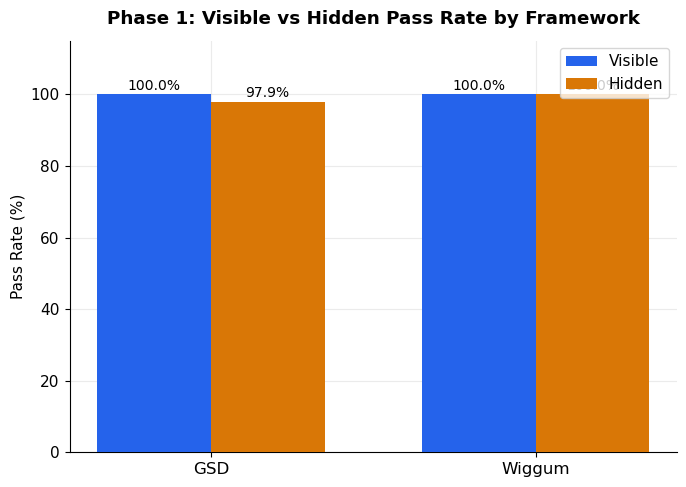

In [27]:
p1 = df[df['phase'] == 'Phase 1']

vis_hid_p1 = (
    p1.groupby('framework')[['visiblePassRate', 'hiddenPassRate']]
    .mean()
    .mul(100)
)

fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(len(vis_hid_p1))
width = 0.35

bars_vis = ax.bar(x - width/2, vis_hid_p1['visiblePassRate'], width,
                  label='Visible', color=GSD_BLUE, zorder=3)

bars_hid = ax.bar(x + width/2, vis_hid_p1['hiddenPassRate'], width,
                  label='Hidden', color=WIG_AMBER, zorder=3)

for bar in bars_vis:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)
    
for bar in bars_hid:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(['GSD', 'Wiggum'], fontsize=12)
ax.set_ylabel('Pass Rate (%)')
ax.set_ylim(0, 115)
ax.set_title('Phase 1: Visible vs Hidden Pass Rate by Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

## Phase 2 visible vs hidden

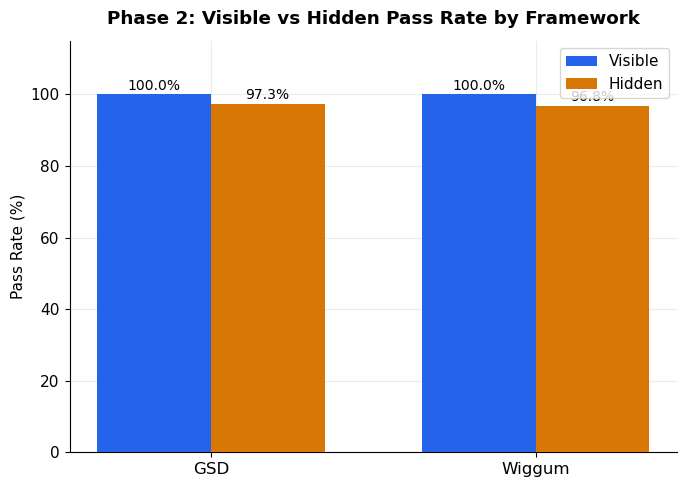

In [28]:
p2 = df[df['phase'] == 'Phase 2']

vis_hid_p2 = (
    p2.groupby('framework')[['visiblePassRate', 'hiddenPassRate']]
    .mean()
    .mul(100)
)

fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(len(vis_hid_p2))
width = 0.35

bars_vis = ax.bar(x - width/2, vis_hid_p2['visiblePassRate'], width,
                  label='Visible', color=GSD_BLUE, zorder=3)

bars_hid = ax.bar(x + width/2, vis_hid_p2['hiddenPassRate'], width,
                  label='Hidden', color=WIG_AMBER, zorder=3)

for bar in bars_vis:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)
    
for bar in bars_hid:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(['GSD', 'Wiggum'], fontsize=12)
ax.set_ylabel('Pass Rate (%)')
ax.set_ylim(0, 115)
ax.set_title('Phase 2: Visible vs Hidden Pass Rate by Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

## Phase 3 hidden vs visible

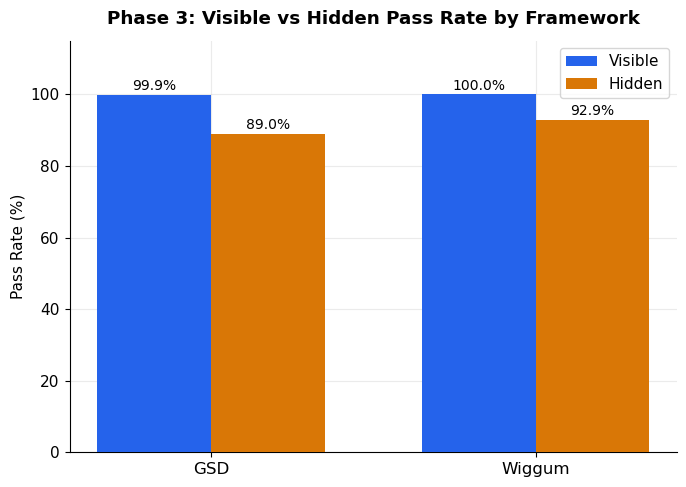

In [29]:
p3 = df[df['phase'] == 'Phase 3']

vis_hid_p3 = (
    p3.groupby('framework')[['visiblePassRate', 'hiddenPassRate']]
    .mean()
    .mul(100)
)

fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(len(vis_hid_p3))
width = 0.35

bars_vis = ax.bar(x - width/2, vis_hid_p3['visiblePassRate'], width,
                  label='Visible', color=GSD_BLUE, zorder=3)

bars_hid = ax.bar(x + width/2, vis_hid_p3['hiddenPassRate'], width,
                  label='Hidden', color=WIG_AMBER, zorder=3)

for bar in bars_vis:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)
    
for bar in bars_hid:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(['GSD', 'Wiggum'], fontsize=12)
ax.set_ylabel('Pass Rate (%)')
ax.set_ylim(0, 115)
ax.set_title('Phase 3: Visible vs Hidden Pass Rate by Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

Both frameworks pass visible tests almost perfectly at every phase (99.9–100%), which is expected since visible tests are available to the agent during execution and function as a feedback signal it can iterate against. The more informative number is the gap to hidden pass rate, the study's built-in robustness/overfitting signal, and that gap tells a different story at each phase.

Phase 1 is where the frameworks diverge most on this specific measure. GSD shows a 2.1-point gap (100% visible vs. 97.9% hidden), while Wiggum shows none at all, a perfect 100% on both. At this complexity tier, Wiggum's solutions generalised completely to the hidden test suite, while GSD's didn't quite. Given Phase 1's overall task simplicity, this reads less as a difference in reasoning depth and more as GSD occasionally satisfying the visible criteria via a slightly different path than the hidden suite expectedm but it's still a genuine, if narrow, robustness edge for Wiggum.

Phase 2 nearly reverses this, though the margins are small. GSD's gap widens slightly to 2.7 points, while Wiggum's gap grows a touch more to 3.2 points. Neither framework's gap grows dramatically at this tier despite the added scaffold complexity, and the two are close enough (0.5 points apart) that this shouldn't be read as a meaningful framework difference, more that added complexity nudges both frameworks' hidden-test generalisation down by a comparable amount.

Phase 3 is where the robustness gap opens up substantially for both frameworks, and where the two families genuinely separate. GSD's gap balloons to 10.9 points (99.9% visible vs. 89.0% hidden); Wiggum's grows too, but to a smaller 7.1 points (100% visible vs. 92.9% hidden). That's a 3.8-point difference in the size of the overfitting gap itself, with GSD generalising noticeably worse under full-stack, cross-layer conditions. This lines up directly with everything else Phase 3 has shown. Wiggum's higher hidden pass rate, its stronger quality scores (especially on Profile Management), and now a smaller gap between what the agent could verify against visible tests and what it actually got right on held-out ones.

Read together, the robustness pattern across all three phases reinforces the study's central emerging finding. That the two frameworks are nearly indistinguishable at low-to-moderate complexity (Phase 1, Phase 2), but under Phase 3's genuinely open-ended, cross-layer conditions, GSD's solutions hold up less well against hidden tests than Wiggum's do, consistent with GSD's persistent, specification-gated context propagating an early misjudgement forward, versus Wiggum's fresh-context restarts re-grounding against the actual repository state at each step.

## Phase 1 robustness gap

In [30]:
p1_gap = df[(df['phase'] == 'Phase 1') & (df['robustnessGap'] > 0)].copy()
p1_gap['taskType'] = p1_gap.apply(
    lambda row: backend_task_types[row['taskId']] if row['target'] == 'backend' else frontend_task_types[row['taskId']],
    axis=1
)

summary_p1_gap = (
    p1_gap.groupby(['taskType', 'framework'])['robustnessGap']
    .agg(['mean', 'count'])
    .round(3)
)

# print(summary_p1_gap)
summary_p1_gap

,,mean,count
taskType,framework,,
Config & Build Fix,gsd,1.000,1
Logical Bug Fix,gsd,0.067,4


### Explanation

Across all 120 Phase 1 runs, only two groups show any overfitting at all, and both belong to GSD. Wiggum does not appear in this table anywhere, meaning every single Wiggum run in Phase 1 passed hidden tests at exactly the same rate as visible tests, zero robustness gap across all 60 of its runs, on every task type and target.

For GSD, Logical Bug Fix shows a small mean gap of 0.067 across 4 runs, a minor, mostly-generalising shortfall rather than a meaningful failure to transfer to hidden tests. Config & Build Fix is the more notable case. A single run with a gap of exactly 1.000, meaning that run passed every visible test while failing every hidden test outright. With a count of 1, this is a single-run event rather than a task-type pattern, but it's a stark one, full overfitting on one specific attempt.

This result sharpens the earlier phase-level comparison, where GSD showed a 2.1-point average robustness gap against Wiggum's zero. Now it's clear that gap isn't spread thinly across GSD's runs, it's concentrated almost entirely in these two backend task types, and largely driven by that one Config & Build Fix run where GSD's solution satisfied the observable tests without actually generalising. Combined with Config & Build Fix already being GSD's weakest correctness task type in Phase 1 (0.90 vs Wiggum's perfect 1.00), this reinforces that Config & Build Fix is specifically where GSD's Phase 1 solutions were least reliable, both in terms of raw correctness and, in at least this one instance, in terms of superficially passing checks without genuinely resolving the task.

## Phase 2 robustness gap

In [31]:
p2_gap = df[(df['phase'] == 'Phase 2') & (df['robustnessGap'] > 0)].copy()
p2_gap['taskType'] = p2_gap.apply(
    lambda row: backend_task_types_p2[row['taskId']] if row['target'] == 'backend' else frontend_task_types_p2[row['taskId']],
    axis=1
)

summary_p2_gap = (
    p2_gap.groupby(['taskType', 'framework'])['robustnessGap']
    .agg(['mean', 'count'])
    .round(3)
)

summary_p2_gap

mean  count
taskType                     framework              
Debounce Implementation      gsd        0.083      4
                             wiggum     0.083      3
Focus Management             gsd        0.200      5
                             wiggum     0.200      5
Rate Limiter Memory & Header wiggum     0.167      2

### Explanation

Debounce Implementation and Focus Management are matched almost exactly between frameworks. Debounce shows an identical mean gap of 0.083 for both GSD (4 runs) and Wiggum (3 runs), and Focus Management shows an identical mean gap of 0.200 for both frameworks across the full 5-run set each. That full-count appearance for Focus Management is worth noting on its own, every single run of this task type, for both frameworks, showed some degree of overfitting to visible tests. Combined with Focus Management already being the shared low point on both correctness and quality in Phase 2, this adds a third dimension to the same story. That this task type isn't just hard to get right and hard to keep clean, it's also the one place in Phase 2 where neither framework reliably produced a solution that held up beyond the tests it could see.

Rate Limiter Memory and Header is the one asymmetric entry. It appears only for Wiggum, with a mean gap of 0.167 across 2 runs, GSD shows no robustness gap on this task type at all. That lines up directly with the correctness results reported earlier, where GSD hit a perfect 1.00 on Rate Limiter Memory and Header while Wiggum trailed slightly at 0.97. Together, these two results tell a consistent story rather than two separate ones. Wiggum's lower correctness on this specific task type is at least partly explained by it satisfying visible tests without fully generalising to the hidden ones, in a couple of its five runs, the kind of overfitting the robustness-gap metric is designed to catch.

So Phase 2's robustness picture is a mirror image of Phase 1's in one respect, where Phase 1 showed GSD as the framework with an isolated overfitting weak point (Config & Build Fix), Phase 2 shows Wiggum with the isolated weak point (Rate Limiter Memory and Header), while the two frameworks otherwise track each other closely, including on their shared struggle with Focus Management. Neither framework shows a broad, consistent robustness advantage at this tier, what differentiation exists is task-type-specific and small in magnitude on both sides.

## Phase 3 robustness gap

In [32]:
p3_gap = df[df['phase'] == 'Phase 3'].copy()
p3_gap['taskType'] = p3_gap['taskId'].map(phase3_task_types)

summary_p3_gap = (
    p3_gap.groupby(['taskType', 'framework'])['robustnessGap']
    .agg(['mean', 'count'])
    .round(3)
)

summary_p3_gap

mean  count
taskType           framework              
Authentication     gsd        0.103     10
                   wiggum     0.056     10
Profile management gsd        0.114     10
                   wiggum     0.086     10

### Explanation

Phase 3 is the only phase where the robustness gap shows up across the full sample rather than being confined to specific task types. Both Authentication and Profile Management show a count of 10 for each framework, meaning every applicable run carried some degree of overfitting to visible tests. That's a step change from Phases 1 and 2, where non-zero gaps were the exception on isolated task types, here they're the norm across the entire tier.

The direction is consistent and runs opposite to the small edges seen at earlier phases. GSD shows the larger gap on both tasks. On Authentication, GSD's mean gap (0.103) is nearly double Wiggum's (0.056). On Profile Management, the gap narrows somewhat but GSD is still higher (0.114 vs Wiggum's 0.086). In both cases, GSD's solutions are satisfying visible tests without generalising to hidden ones more often, or more severely, than Wiggum's.

This lines up cleanly with everything else Phase 3 has shown so far. Wiggum's higher hidden pass rate on both tasks, its quality-score advantage (particularly the 0.09 gap on Profile Management), and the phase-level robustness comparison, where GSD's overall gap (10.9 points) was substantially larger than Wiggum's (7.1 points). This task-level breakdown is what's actually producing that phase-level difference, it isn't diffuse noise, it's a real, consistent pattern across both Phase 3 tasks.

Both frameworks' gaps also grow from Authentication to Profile Management, GSD from 0.103 to 0.114, Wiggum from 0.056 to 0.086, which fits the inherited-state design of Phase 3. Whatever imperfections either framework's Authentication output carried forward seem to have compounded, mildly, into a larger generalisation gap on the downstream task, for both frameworks alike, even though Wiggum's absolute gap stays smaller throughout.

Taken together, this is the strongest and most consistent robustness-based evidence in the study for a genuine framework effect. Under Phase 3's full-stack, cross-layer, inherited-state conditions, GSD's solutions generalise measurably less well to hidden tests than Wiggum's do. That's the same direction as the correctness and quality findings for this phase, and it's the first point in the robustness analysis where the pattern holds across an entire tier rather than surfacing on one or two isolated task types.

# 4.4 Efficiency Metrics

## Cost

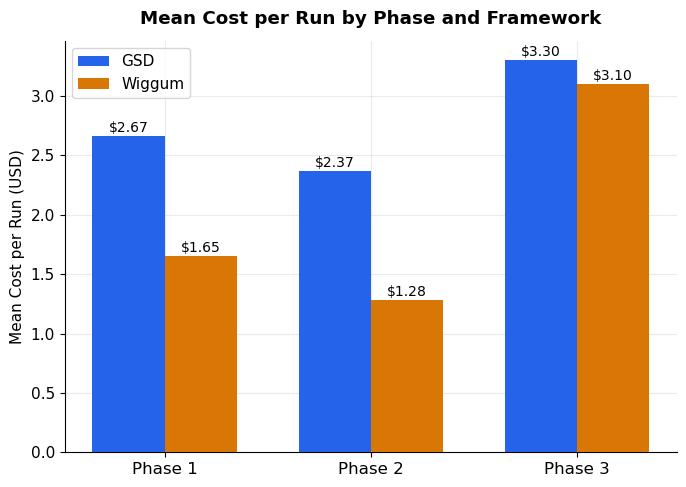

In [33]:
cost_by_phase = (
    df.groupby(['phase', 'framework'])['costUsd']
    .mean()
    .unstack('framework')
)

phase_order = ['Phase 1', 'Phase 2', 'Phase 3']
cost_by_phase = cost_by_phase.reindex(phase_order)

fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(len(cost_by_phase))
width = 0.35

bars_gsd = ax.bar(x - width/2, cost_by_phase['gsd'], width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, cost_by_phase['wiggum'], width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'${bar.get_height():.2f}', ha='center', va='bottom', fontsize=10)
    
for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'${bar.get_height():.2f}', ha='center', va='bottom', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(phase_order, fontsize=12)
ax.set_ylabel('Mean Cost per Run (USD)')
ax.set_title('Mean Cost per Run by Phase and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

GSD is more expensive than Wiggum in absolute terms at every phase, but the size of that premium moves in an unexpected direction across the study. Phase 1 shows a `$2.67` (GSD) vs `$1.65` (Wiggum) split, a ratio of roughly 1.6×. Phase 2 shows the widest relative gap: `$2.37` vs `$1.28`, a ratio of about 1.85×. Phase 3, however, narrows dramatically to `$3.30` vs `$3.10`, a ratio of just 1.07×, meaning the two frameworks are nearly cost-equivalent at the highest complexity tier.

What's driving that narrowing is Wiggum's cost, not GSD's. From Phase 2 to Phase 3, GSD's cost rises from `$2.37` to `$3.30`, a `$0.93` increase (about 39%). Wiggum's rises from `$1.28` to `$3.10`, a $1.82 increase, more than double its Phase 2 cost, and roughly twice the absolute increase GSD experienced. Wiggum's efficiency advantage, which held comfortably through Phase 1 and Phase 2, effectively disappears under Phase 3's full-stack, cross-layer conditions.

This is a meaningful qualification to layer onto the correctness, quality, and robustness results from Phase 3, all of which favoured Wiggum. Those advantages did not come at a lower cost in Phase 3 the way they did at earlier tiers, Wiggum's restart-and-rebuild mechanism, which discards reasoning and re-derives understanding from the specification and repo state at every cycle, plausibly requires substantially more restart cycles (and therefore more tokens and cost) to work through genuinely novel, cross-layer architectural decisions than it does on the more bounded modify/fix tasks that make up Phases 1 and 2. GSD's phase-gated structure, by contrast, scales in cost more moderately here, even though it's already paying an overhead for its verification steps at every tier.

Put together, the Phase 3 picture is more nuanced than "Wiggum wins". It produces better correctness, quality, and robustness outcomes at this tier, but very nearly at parity in cost rather than at its earlier discount.

## Time

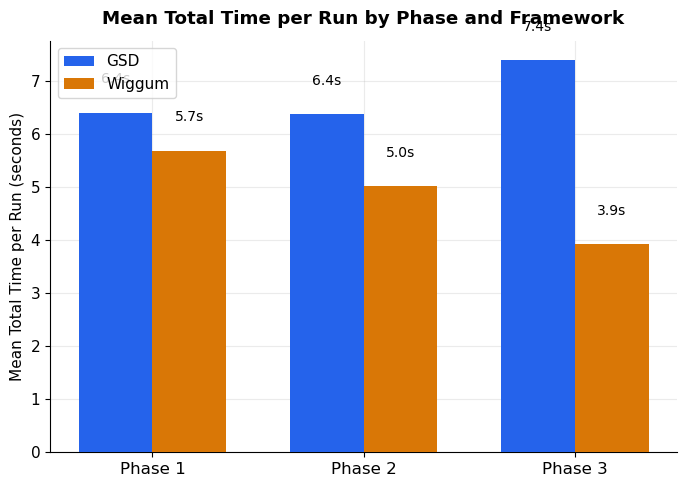

In [34]:
time_by_phase = (
    df.groupby(['phase', 'framework'])['totalMs']
    .mean()
    .unstack('framework')
)

time_by_phase = time_by_phase.reindex(phase_order)

fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(len(time_by_phase))
width = 0.35

bars_gsd = ax.bar(x - width/2, time_by_phase['gsd'] / 1000, width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, time_by_phase['wiggum'] / 1000, width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}s', ha='center', va='bottom', fontsize=10)
    
for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}s', ha='center', va='bottom', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(phase_order, fontsize=12)
ax.set_ylabel('Mean Total Time per Run (seconds)')
ax.set_title('Mean Total Time per Run by Phase and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

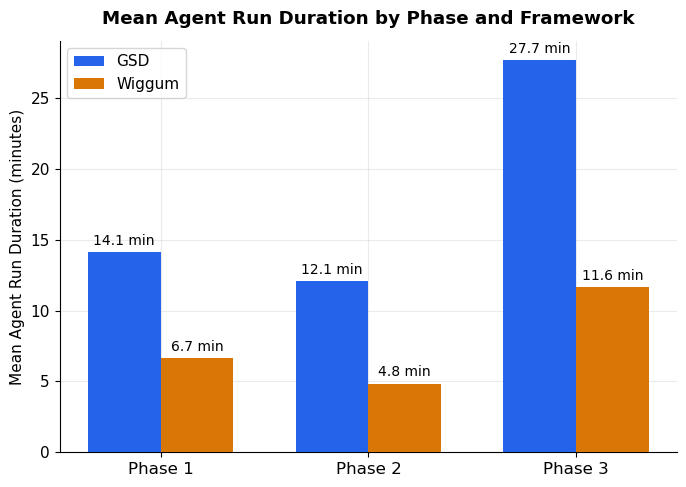

In [35]:
time_by_phase = (
    df.groupby(['phase', 'framework'])['wallDurationMs']
    .mean()
    .unstack('framework')
)

time_by_phase = time_by_phase.reindex(phase_order)

fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(len(time_by_phase))
width = 0.35

bars_gsd = ax.bar(x - width/2, time_by_phase['gsd'] / 60000, width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, time_by_phase['wiggum'] / 60000, width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{bar.get_height():.1f} min', ha='center', va='bottom', fontsize=10)

for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{bar.get_height():.1f} min', ha='center', va='bottom', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(phase_order, fontsize=12)
ax.set_ylabel('Mean Agent Run Duration (minutes)')
ax.set_title('Mean Agent Run Duration by Phase and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

Time shows a consistent direction that time didn't flip the way cost did. GSD takes longer than Wiggum at every phase, 6.4s vs 5.7s in Phase 1, 6.4s vs 5.0s in Phase 2, and 7.4s vs 3.9s in Phase 3. Unlike the cost comparison, where GSD's relative premium narrowed sharply in Phase 3, the time gap actually widens there, from a 0.7s difference in Phase 1, to 1.4s in Phase 2, to 3.5s in Phase 3, where GSD takes almost twice as long as Wiggum.

That combination, cost converging while time diverges in Phase 3, is worth pulling apart, because it changes what "efficiency" actually means at this tier. If you divide cost by time to get a rough spend rate, GSD sits at roughly `$0.42`/s in Phase 1 and `$0.37`/s in Phase 2, consistently spending faster per second than Wiggum (`$0.29`/s and `$0.26`/s respectively) across both earlier phases. In Phase 3, that relationship flips. GSD's rate stays fairly stable at about `$0.45`/s, but Wiggum's jumps to roughly `$0.80`/s, nearly double GSD's rate, even though Wiggum finishes the run in under half the wall-clock time.

That's consistent with what the cost result already implied. Wiggum's Phase 3 cost increase isn't coming from working longer, it's coming from working faster but far more intensively per unit time. That fits its restart mechanism directly, each restart discards context and re-invokes the agent fresh, so under Phase 3's genuinely novel, cross-layer reasoning demands, Wiggum likely needed to burn through several dense, token-heavy restart cycles in quick succession rather than one longer, steadier reasoning pass. GSD's phase-gated structure, by contrast, spreads its (still higher) cost over comparatively more time at every tier, consistent with a steadier verification-and-execution rhythm rather than repeated fresh starts.

So the fuller efficiency picture for Phase 3 is that Wiggum remains faster and very slightly cheaper in dollar terms, but it's achieving that by spending at close to double the rate per second that GSD does. This means its efficiency advantage at this tier is really a time-efficiency advantage, not the clear cost-and-time advantage it held in Phase 1 and 2. That's an important nuance for RQ2, Wiggum's correctness, quality, and robustness edge in Phase 3 comes bundled with a much steeper resource-intensity profile per second of execution, even though total wall-clock time and total spend both still favour it narrowly overall.

## Iterations

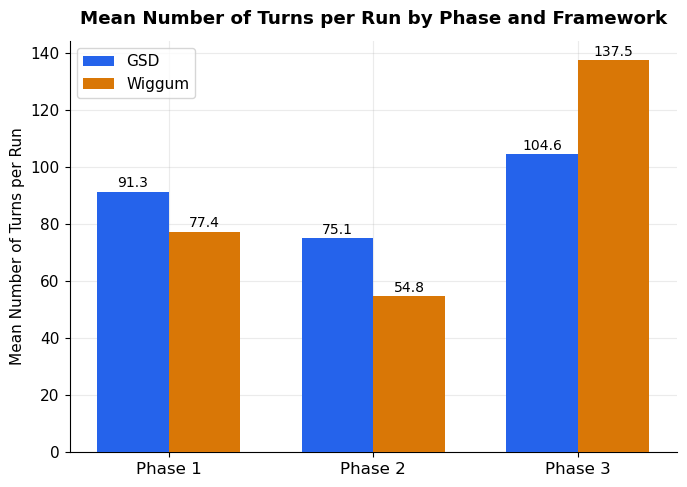

In [35]:
turns_by_phase = (
    df.groupby(['phase', 'framework'])['numTurns']
    .mean()
    .unstack('framework')
)

turns_by_phase = turns_by_phase.reindex(phase_order)

fig, ax = plt.subplots(figsize=(7, 5))

x = np.arange(len(turns_by_phase))
width = 0.35

bars_gsd = ax.bar(x - width/2, turns_by_phase['gsd'], width,
                  label='GSD', color=GSD_BLUE, zorder=3)

bars_wig = ax.bar(x + width/2, turns_by_phase['wiggum'], width,
                  label='Wiggum', color=WIG_AMBER, zorder=3)

for bar in bars_gsd:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=10)
    
for bar in bars_wig:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(phase_order, fontsize=12)
ax.set_ylabel('Mean Number of Turns per Run')
ax.set_title('Mean Number of Turns per Run by Phase and Framework', fontweight='bold', pad=12)
ax.legend()

plt.tight_layout()
plt.show()

### Explanation

Turns follow a broadly similar shape to cost and time in Phase 1 and 2, but produce the sharpest reversal yet in Phase 3.

In Phase 1, GSD averages 91.3 turns against Wiggum's 77.4 (GSD +13.9). In Phase 2, the gap widens slightly to 75.1 vs 54.8 (GSD +20.3). Both phases show GSD needing more iterations per run than Wiggum, consistent with the cost picture at those tiers, where GSD was also the more expensive framework

Phase 3 breaks that pattern entirely. Wiggum jumps to 137.5 turns against GSD's 104.6, a 32.9-turn gap that flips direction and is the largest turn-count difference anywhere in the study. Wiggum now needs substantially more iterations than GSD, the opposite of what held in Phase 1 and 2.

This reconciles neatly with the time and cost results from Phase 3 rather than contradicting them. Wiggum finished Phase 3 runs faster overall (3.9s vs GSD's 7.4s) despite taking far more turns, which only works if each individual Wiggum turn is considerably quicker than each GSD turn. Dividing time by turns bears this out, roughly 0.028 seconds per turn for Wiggum against roughly 0.071 seconds per turn for GSD, about 2.5× faster per turn. The same logic applies to cost. Wiggum's cost per turn works out to roughly `$0.023`, cheaper than GSD's roughly `$0.032` per turn, yet Wiggum's much higher turn count is what pulls its total Phase 3 cost up to nearly match GSD's overall, rather than staying at the discount it held in earlier phases.

Put plainly, Wiggum's Phase 3 profile is many short, cheap, fast turns. GSD's is fewer, longer, more expensive turns. That maps directly onto the two frameworks' underlying mechanics, Wiggum's restart-based loop invokes the agent fresh, one bounded phase at a time, so under genuine full-stack complexity it simply needs many more of these bounded cycles to converge, each one quick and inexpensive individually. GSD's persistent, phase-gated approach does more work per invocation, so it needs fewer but heavier turns to reach the same point.

This closes the efficiency picture for the study. GSD's overhead in Phase 1 and 2 shows up consistently across cost and turns (more of both, at a fairly steady rate), while Wiggum's overhead in Phase 3 shows up specifically as turn-count volume rather than time or per-turn cost. Given Wiggum still comes out ahead on correctness, quality, and robustness in Phase 3, the practical implication is that its advantage there isn't "free" in the way it looked in earlier phases, it's paid for in a large number of rapid restart cycles rather than in wall-clock time or cost-per-action, which is a materially different kind of overhead than GSD's, even where the two frameworks land close together on total dollars spent.

# 4.6 Reproducibility

## Phase 1 Reproducibility

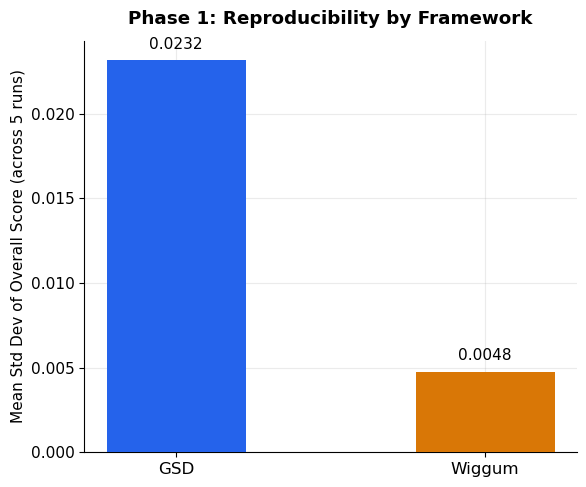

In [36]:
p1 = df[df['phase'] == 'Phase 1']

std_p1 = (
    p1.groupby(['taskId', 'target', 'framework'])['overallScore']
    .std()
    .reset_index()
    .groupby('framework')['overallScore']
    .mean()
)

fig, ax = plt.subplots(figsize=(6, 5))

x = np.arange(len(std_p1))
width = 0.45
colors = [GSD_BLUE, WIG_AMBER]

bars = ax.bar(x, std_p1, width, color=colors, zorder=3)

for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0005,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(['GSD', 'Wiggum'], fontsize=12)
ax.set_ylabel('Mean Std Dev of Overall Score (across 5 runs)')
ax.set_title('Phase 1: Reproducibility by Framework', fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

### Explanation

GSD shows a mean standard deviation of 0.0232, against Wiggum's 0.0048. GSD's run-to-run variance is roughly 4.8× higher. Both figures are low in absolute terms (neither framework is wildly unstable), but this is a real and fairly sizeable relative gap rather than the near-parity seen in most of the correctness and quality comparisons at this tier.w.This is a notable pairing with the earlier Phase 1 findings. GSD's single Config & Build Fix run with a robustness gap of 1.000, and its lower correctness on that same task type (0.90 vs Wiggum's perfect 1.00), both point to GSD being the less consistent framework specifically on that task. A higher mean standard deviation across all Phase 1 tasks is consistent with that, it suggests GSD's variability isn't confined to one flagged task type alone, but shows up more broadly as a tendency toward less run-to-run consistency than Wiggum, even where mean scores between the two frameworks look similar.

Wiggum's markedly lower variance (0.0048) fits its restart-based design in a specific way. Because each cycle re-derives its understanding from the specification, plan status, and current repository state rather than carrying forward a long reasoning chain, its outcomes may be less sensitive to the particular reasoning path any single run happens to take. GSD's persistent, multi-phase context, by contrast, gives more surface area for a given run's early reasoning or planning choices to compound differently across repeated attempts, which could plausibly produce more spread in outcomes even when the mean result is comparable.

This is a meaningful early data point for the reproducibility dimension of RQ2. At the lowest complexity tier, Wiggum is not just competitive with GSD on average outcomes, it appears to be the more consistent framework run-to-run. Whether that reproducibility advantage holds, narrows, or reverses as task complexity increases is the key question for the Phase 2 and Phase 3 versions of this comparison.w.

## Phase 2 reproducibility

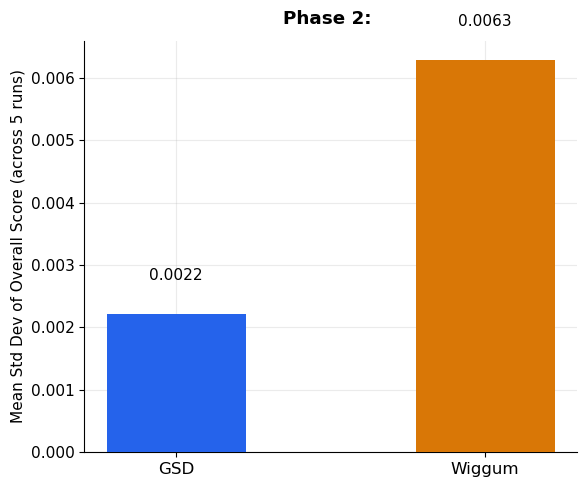

In [38]:
p2 = df[df['phase'] == 'Phase 2']

std_p2 = (
    p2.groupby(['taskId', 'target', 'framework'])['overallScore']
    .std()
    .reset_index()
    .groupby('framework')['overallScore']
    .mean()
)

fig, ax = plt.subplots(figsize=(6, 5))

x = np.arange(len(std_p2))
width = 0.45
colors = [GSD_BLUE, WIG_AMBER]

bars = ax.bar(x, std_p2, width, color=colors, zorder=3)

for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0005,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(['GSD', 'Wiggum'], fontsize=12)
ax.set_ylabel('Mean Std Dev of Overall Score (across 5 runs)')
ax.set_title('Phase 2: ', fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

### Explanation

Phase 2 reverses the Phase 1 pattern outright. GSD's variance drops to 0.0022, lower than either framework showed in Phase 1, while Wiggum's rises to 0.0063, roughly 2.9× higher than GSD's. Where Phase 1 had GSD as the noticeably less consistent framework, Phase 2 flips that: GSD is now the more reproducible of the two.

Both figures are still small in absolute terms, so this shouldn't be read as either framework becoming unreliable. But the direction of the swing is worth sitting with. GSD went from its least consistent showing in the study (0.0232) to its most consistent (0.0022) between Phase 1 and Phase 2, while Wiggum moved the opposite way, from its most consistent showing (0.0048) to a somewhat higher variance (0.0063).

One plausible explanation ties back to what Phase 2 actually changed. The scaffold got substantially more architecturally demanding (React contexts, SQLite persistence, typed error hierarchies, centralised middleware), while the tasks themselves stayed relatively scoped to fixing or extending a bounded piece of that scaffold, as the earlier build-success discussion noted. That's exactly the kind of environment where GSD's upfront requirements-clarification and verification-gated execution could pay off in consistency, a more heavily-specified scaffold gives GSD's explicit success criteria more to anchor against, run to run. Wiggum's fresh-context restarts, by contrast, have to re-derive an understanding of a now more complex codebase from scratch at every cycle, which could introduce more room for a given run's interpretation to vary.

So reproducibility doesn't show a stable framework-level ordering across the study so far, it flips between Phase 1 and Phase 2, with each framework taking a turn as the more consistent one. That makes the Phase 3 result the deciding data point for this dimension, whether GSD holds onto its Phase 2 consistency advantage, or whether Phase 3's full-stack, cross-layer conditions (which have favoured Wiggum on nearly every other metric) push reproducibility back in Wiggum's direction too.

## Phase 3 reproducibility

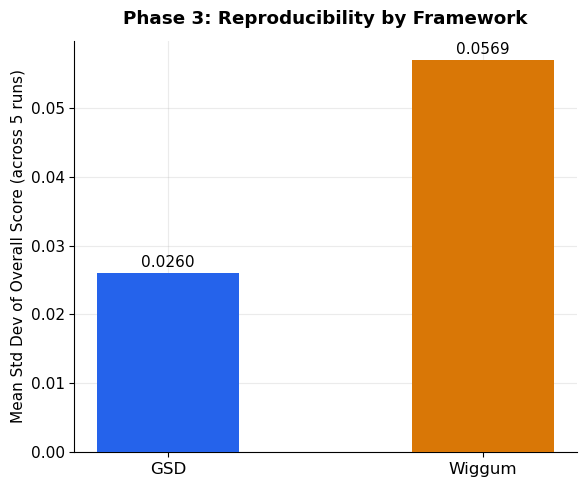

In [39]:
p3 = df[df['phase'] == 'Phase 3']

std_p3 = (
    p3.groupby(['taskId', 'target', 'framework'])['overallScore']
    .std()
    .reset_index()
    .groupby('framework')['overallScore']
    .mean()
)

fig, ax = plt.subplots(figsize=(6, 5))

x = np.arange(len(std_p3))
width = 0.45
colors = [GSD_BLUE, WIG_AMBER]

bars = ax.bar(x, std_p3, width, color=colors, zorder=3)

for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0005,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(['GSD', 'Wiggum'], fontsize=12)
ax.set_ylabel('Mean Std Dev of Overall Score (across 5 runs)')
ax.set_title('Phase 3: Reproducibility by Framework', fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

### Explanation

Phase 3 shows the largest reproducibility gap in the study, and GSD comes out as the more consistent framework. GSD's variance is 0.0260 against Wiggum's 0.0569. Wiggum's run-to-run variance is more than double GSD's at the tier where task complexity peaks.

Looking at all three phases together, a clear pattern emerges rather than a series of one-off flips. GSD held the higher variance only in Phase 1 (0.0232 vs Wiggum's 0.0048). From Phase 2 onward, GSD is consistently the more reproducible framework (0.0022 vs 0.0063 in Phase 2, 0.0260 vs 0.0569 in Phase 3). Wiggum's variance also grows far more steeply across phases than GSD's does, roughly a 9× increase from Phase 2 to Phase 3, against GSD's roughly 12× increase from a much smaller base, but landing at a level still well below Wiggum's.

This is an important qualifier on the Phase 3 story so far. Wiggum has shown a consistent advantage across correctness, quality, and robustness at this tier, but it's now clear that advantage comes with meaningfully more run-to-run variability than GSD produces. Wiggum's better average outcome in Phase 3 doesn't mean a more predictable one. A given Wiggum run on these full-stack tasks is more likely to land somewhere noticeably different from its other four runs than a given GSD run is. GSD, despite trailing on mean correctness, quality, and robustness at this tier, is the more dependable framework in the specific sense of producing a tighter spread of outcomes.

That's a useful nuance for the study's central comparison. It suggests GSD's verification-gated structure isn't paying off in better average outcomes at the hardest tier, but it may still be doing what it's designed to do in a narrower sense. That is, constraining the variance of what gets produced, even when the central tendency of that output is lower than Wiggum's. Framed against RQ2, this reframes the Phase 3 conclusion from a simple "Wiggum performs better" into something closer to, Wiggum trades consistency for a higher average outcome under full-stack, cross-layer conditions, while GSD trades average outcome for tighter, more predictable results, a framework-level trade-off rather than an unambiguous win for either design philosophy.

# Summary: How Different Agentic Frameworks Impact AI-Assisted Software Development

## 1.1 Which framework achieves the highest task success rate?
Neither framework holds a consistent success-rate advantage, and what edge exists narrows as complexity rises. Build success showed a marginal GSD gap in Phase 1 (96.7% frontend vs Wiggum's 100%; both 100% backend) that disappeared entirely in Phase 2 and 3, where both frameworks reached a perfect 100% across all targets. Hidden pass rate, the more meaningful correctness measure, told a more differentiated story than build success alone. Near-total convergence in Phase 1 and Phase 2 (within 0.8–3.3 points on either target), giving way in Phase 3 to a consistent Wiggum advantage on both frontend (91.4% vs 86.9%) and backend (94.5% vs 91.1%). So task success is largely framework-agnostic at low-to-moderate complexity, but under Phase 3's full-stack, inherited-state conditions, Wiggum reaches meaningfully higher correctness than GSD.

## 1.2 Which framework produces higher-quality and more maintainable code?
Quality is where framework design mattered most, and the answer is complexity-dependent rather than absolute. In Phase 1, GSD produced higher quality output on precision-driven, deterministic tasks (Syntax Bug Fix, Config & Build Fix, Security & Validation), while Wiggum produced higher quality output on tasks requiring flexible, exploratory reasoning (Feature Implementation, Integration, API Contract Fix). Phase 2 saw near-total convergence in quality between frameworks. Phase 3 produced the most consequential result in the study: both frameworks' quality collapsed on T3-1, but Wiggum recovered substantially more on T3-2 (0.77 vs GSD's 0.66), the largest single quality gap observed. Overall, GSD's structured approach favours precision tasks; Wiggum's iterative flexibility favours adaptive, incrementally-built tasks, especially under compounding complexity.

Quality showed the least framework differentiation at Phase 1 and 2, and the most at Phase 3. Phase 1 frontend quality was nearly identical between frameworks on every task type. Phase 1 backend showed the one standout early result, GSD trailing Wiggum by 0.09 on Security & Validation, the single largest quality gap outside Phase 3, and notable given security carries the heaviest penalty weighting in the scoring model. Phase 2 was close to a complete tie on both targets. Phase 3 produced the sharpest quality effect in the study. Both frameworks' quality collapsed to well below any earlier result (0.32–0.45), but Wiggum recovered further on Profile Management (0.54 vs GSD's 0.45), a gap that, combined with a smaller correctness edge, explains Wiggum's clear overall-score lead on that task. Taken together, quality doesn't show a stable "GSD wins precision tasks, Wiggum wins exploratory tasks" split in this dataset. The one clear, sizeable quality gap in Phases 1 and 2 (Security & Validation) already favoured Wiggum, and Phase 3 reinforces the same direction under harder conditions.

## 1.3 How do frameworks compare in efficiency (time, token, cost)?
GSD is consistently the more expensive framework, but the size and shape of that premium shifts across phases. In cost, GSD's relative premium is largest in Phase 2 (1.85×) and Phase 1 (1.62×), then narrows to near-parity in Phase 3 (1.07×, `$3.30` vs `$3.10`), driven by Wiggum's cost more than doubling between Phase 2 and 3. In time, the pattern moves the opposite way. GSD is slower at every phase, and that gap widens sharply in Phase 3 (7.4s vs 3.9s). In turns, GSD requires more iterations in Phase 1 and 2, but Phase 3 reverses this outright, Wiggum needs substantially more turns (137.5 vs GSD's 104.6). Read together, Wiggum's Phase 3 profile is many short, cheap, fast turns, while GSD's is fewer, longer, costlier ones. Wiggum's per-second cost rate in Phase 3 (~ `$0.80`/s) is nearly double GSD's (~`$0.45`/s), meaning Wiggum's Phase 3 competitiveness on cost and time is bought with a much more resource-intensive execution rhythm, not a cheaper one in any simple sense.

## 1.4 Which framework is more reproducible across repeated runs?
Reproducibility does not favour one framework consistently, and it flips at every phase. GSD showed higher variance (less consistency) than Wiggum in Phase 1 (0.0232 vs 0.0048). That reversed in Phase 2, where GSD became the more consistent framework (0.0022 vs 0.0063), and GSD held that advantage into Phase 3 as well (0.0260 vs 0.0569), despite Wiggum's better average correctness, quality, and robustness at that tier. This is one of the more important nuances in the study. Wiggum's superior mean outcomes in Phase 3 come with meaningfully more run-to-run spread than GSD's, so Wiggum's Phase 3 advantage is a better-average, less-predictable one, while GSD trades a lower average outcome for a tighter, more dependable spread of results.

## 1.5 How do frameworks perform across different task types?
Task type is the dominant driver of variation for most of the study, with framework identity mattering less until Phase 3. Both frameworks shared common weak points regardless of design, Config & Build Fix in Phase 1 (where correctness and robustness both dipped for GSD specifically), and Focus Management in Phase 2, which was the shared quality and correctness floor for both frameworks across every measure. Where frameworks did diverge by task type, the direction was inconsistent in Phase 1 and 2 (small, roughly balanced gaps in both directions across API Contract Fix, Rate Limiter, Debounce, Service Layer Refactoring), but became one-directional in Phase 3, where Wiggum led on both Authentication and, more substantially, Profile Management, the task that inherits state from Authentication's output. This supports a complexity-contingent reading that task type explains most of the variance at low-to-moderate complexity, while framework design becomes the more decisive factor specifically under full-stack, cross-layer, inherited-state conditions.

## Overarching conclusion
The evidence does not support a universal "better" framework, but it does support a complexity-contingent one. At Phase 1 and Phase 2 complexity, GSD and Wiggum are close to functionally equivalent across correctness, quality, and reproducibility, with GSD paying a consistent cost-and-turns premium for no corresponding, broad quality advantage, apart from one clear Phase 1 exception where Wiggum showed a meaningful security-related quality edge. Under Phase 3's genuinely open-ended, cross-layer, inherited-state conditions, the two frameworks separate more decisively. Wiggum achieves higher correctness, higher quality on the state-inheriting task, and a smaller hidden-test generalisation gap, while GSD retains an advantage in reproducibility and, on cost specifically, closes most of its earlier gap. Neither framework's structural philosophy, specification-first verification versus restart-based re-grounding, converts cleanly into superiority once complexity is accounted for. Instead, each trades a different resource (cost, turns, or consistency) for a different kind of outcome (correctness, quality, or predictability), and which trade-off is worth making depends on the complexity and coordination demands of the task at hand rather than on either framework's design being categorically stronger.